In [2]:
import pandas as pd
import numpy as np
import re
import html

from urllib.parse import unquote, urlparse

In [3]:
df=pd.read_csv('csic_database.csv')

In [4]:
df.head(5)

,Unnamed: 0,Method,User-Agent,Pragma,Cache-Control,Accept,Accept-encoding,Accept-charset,language,host,cookie,content-type,connection,lenght,content,classification,URL
0,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=1F767F17239C9B670A39E9B10C3825F4,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/index.jsp HTTP/1.1
1,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=81761ACA043B0E6014CA42A4BCD06AB5,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/anadir.j...
2,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=933185092E0B668B90676E0A2B0767AF,application/x-www-form-urlencoded,Connection: close,Content-Length: 68,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0,http://localhost:8080/tienda1/publico/anadir.j...
3,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=8FA18BA82C5336D03D3A8AFA3E68CBB0,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/autentic...
4,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=7104E6C68A6BCF1423DAE990CE49FEE2,application/x-www-form-urlencoded,Connection: close,Content-Length: 63,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0,http://localhost:8080/tienda1/publico/autentic...


In [5]:
df.describe()

,classification
count,61065.000000
mean,0.410464
std,0.491922
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [6]:
print(df.shape)

(61065, 17)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61065 entries, 0 to 61064
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       61065 non-null  object
 1   Method           61065 non-null  object
 2   User-Agent       61065 non-null  object
 3   Pragma           61065 non-null  object
 4   Cache-Control    61065 non-null  object
 5   Accept           60668 non-null  object
 6   Accept-encoding  61065 non-null  object
 7   Accept-charset   61065 non-null  object
 8   language         61065 non-null  object
 9   host             61065 non-null  object
 10  cookie           61065 non-null  object
 11  content-type     17977 non-null  object
 12  connection       61065 non-null  object
 13  lenght           17977 non-null  object
 14  content          17977 non-null  object
 15  classification   61065 non-null  int64 
 16  URL              61065 non-null  object
dtypes: int64(1), object(16)
memory 

In [8]:
print(df.columns.tolist)

<bound method IndexOpsMixin.tolist of Index(['Unnamed: 0', 'Method', 'User-Agent', 'Pragma', 'Cache-Control',
       'Accept', 'Accept-encoding', 'Accept-charset', 'language', 'host',
       'cookie', 'content-type', 'connection', 'lenght', 'content',
       'classification', 'URL'],
      dtype='object')>


In [9]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

In [10]:
df.head()

,unnamed:_0,method,user_agent,pragma,cache_control,accept,accept_encoding,accept_charset,language,host,cookie,content_type,connection,lenght,content,classification,url
0,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=1F767F17239C9B670A39E9B10C3825F4,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/index.jsp HTTP/1.1
1,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=81761ACA043B0E6014CA42A4BCD06AB5,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/anadir.j...
2,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=933185092E0B668B90676E0A2B0767AF,application/x-www-form-urlencoded,Connection: close,Content-Length: 68,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0,http://localhost:8080/tienda1/publico/anadir.j...
3,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=8FA18BA82C5336D03D3A8AFA3E68CBB0,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/autentic...
4,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=7104E6C68A6BCF1423DAE990CE49FEE2,application/x-www-form-urlencoded,Connection: close,Content-Length: 63,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0,http://localhost:8080/tienda1/publico/autentic...


In [11]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [12]:
print(df.columns.tolist())

['unnamed:_0', 'method', 'user_agent', 'pragma', 'cache_control', 'accept', 'accept_encoding', 'accept_charset', 'language', 'host', 'cookie', 'content_type', 'connection', 'lenght', 'content', 'classification', 'url']


In [13]:
if "Unnamed: 0" in df.columns:
    print(df["Unnamed: 0"].head(10))
    print(df["Unnamed: 0"].tail(10))
else:
    print("'Unnamed: 0' column does not exist")

'Unnamed: 0' column does not exist


In [14]:
print("Columns in df:")
print(df.columns.tolist())

print("\nShape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Columns in df:
['unnamed:_0', 'method', 'user_agent', 'pragma', 'cache_control', 'accept', 'accept_encoding', 'accept_charset', 'language', 'host', 'cookie', 'content_type', 'connection', 'lenght', 'content', 'classification', 'url']

Shape:
(61065, 17)

First 5 rows:


,unnamed:_0,method,user_agent,pragma,cache_control,accept,accept_encoding,accept_charset,language,host,cookie,content_type,connection,lenght,content,classification,url
0,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=1F767F17239C9B670A39E9B10C3825F4,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/index.jsp HTTP/1.1
1,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=81761ACA043B0E6014CA42A4BCD06AB5,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/anadir.j...
2,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=933185092E0B668B90676E0A2B0767AF,application/x-www-form-urlencoded,Connection: close,Content-Length: 68,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0,http://localhost:8080/tienda1/publico/anadir.j...
3,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=8FA18BA82C5336D03D3A8AFA3E68CBB0,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/autentic...
4,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=7104E6C68A6BCF1423DAE990CE49FEE2,application/x-www-form-urlencoded,Connection: close,Content-Length: 63,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0,http://localhost:8080/tienda1/publico/autentic...


In [15]:
df.columns = df.columns.astype(str).str.strip()

print(df.columns.tolist())

['unnamed:_0', 'method', 'user_agent', 'pragma', 'cache_control', 'accept', 'accept_encoding', 'accept_charset', 'language', 'host', 'cookie', 'content_type', 'connection', 'lenght', 'content', 'classification', 'url']


In [16]:
if "Method" in df.columns:
    print(df["Method"].value_counts(dropna=False))
else:
    print("Method column NOT FOUND")

Method column NOT FOUND


In [17]:
method_col = [col for col in df.columns 
              if str(col).strip().lower() == "method"]

print(method_col)

['method']


In [18]:
print(df[method_col[0]].value_counts(dropna=False))

method
GET     43088
POST    17580
PUT       397
Name: count, dtype: int64


In [19]:
print(df["classification"].value_counts())

classification
0    36000
1    25065
Name: count, dtype: int64


In [20]:
print(
    df["classification"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

classification
0    58.95
1    41.05
Name: proportion, dtype: float64


In [21]:
# 0 or 1 ko compare karne ke liye classification column ka use karenge. 0 ka matlab hai normal traffic aur 1 ka matlab hai attack traffic.
print("Available columns:")
print(df.columns.tolist())

print("\nCLASSIFICATION 0:")
display(
    df[df["classification"] == 0].head(10)
)

print("\nCLASSIFICATION 1:")
display(
    df[df["classification"] == 1].head(10)
)



Available columns:
['unnamed:_0', 'method', 'user_agent', 'pragma', 'cache_control', 'accept', 'accept_encoding', 'accept_charset', 'language', 'host', 'cookie', 'content_type', 'connection', 'lenght', 'content', 'classification', 'url']

CLASSIFICATION 0:


,unnamed:_0,method,user_agent,pragma,cache_control,accept,accept_encoding,accept_charset,language,host,cookie,content_type,connection,lenght,content,classification,url
0,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=1F767F17239C9B670A39E9B10C3825F4,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/index.jsp HTTP/1.1
1,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=81761ACA043B0E6014CA42A4BCD06AB5,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/anadir.j...
2,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=933185092E0B668B90676E0A2B0767AF,application/x-www-form-urlencoded,Connection: close,Content-Length: 68,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0,http://localhost:8080/tienda1/publico/anadir.j...
3,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=8FA18BA82C5336D03D3A8AFA3E68CBB0,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/autentic...
4,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=7104E6C68A6BCF1423DAE990CE49FEE2,application/x-www-form-urlencoded,Connection: close,Content-Length: 63,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0,http://localhost:8080/tienda1/publico/autentic...
5,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=5254A7A7C7F0E74D699E6A9C9487795A,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/caracter...
6,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=417DBC69B2F909CCD574CFC69F56779F,application/x-www-form-urlencoded,Connection: close,Content-Length: 4,id=2,0,http://localhost:8080/tienda1/publico/caracter...
7,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=42B53DB3F82E67BBB24E57E9CDC8E008,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/carrito....
8,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=A651CE9798E1B71FCA9D9B2159432A22,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/entrar.j...
9,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=EE6A06EE8174FC2B05432AA5A0FCE998,application/x-www-form-urlencoded,Connection: close,Content-Length: 33,errorMsg=Credenciales+incorrectas,0,http://localhost:8080/tienda1/publico/entrar.j...



CLASSIFICATION 1:


,unnamed:_0,method,user_agent,pragma,cache_control,accept,accept_encoding,accept_charset,language,host,cookie,content_type,connection,lenght,content,classification,url
36000,Anomalous,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=B92A8B48B9008CD29F622A994E0F650D,NaN,close,NaN,NaN,1,http://localhost:8080/tienda1/publico/anadir.j...
36001,Anomalous,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=AE29AEEBDE479D5E1A18B4108C8E3CE0,application/x-www-form-urlencoded,Connection: close,Content-Length: 146,id=2&nombre=Jam%F3n+Ib%E9rico&precio=85&cantid...,1,http://localhost:8080/tienda1/publico/anadir.j...
36002,Anomalous,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=F563B5262843F12ECAE41815ABDEEA54,NaN,close,NaN,NaN,1,http://localhost:8080/tienda1/publico/anadir.j...
36003,Anomalous,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=3B654D6DF7F1466EE80D7F756B00E5D1,application/x-www-form-urlencoded,Connection: close,Content-Length: 77,id=2%2F&nombre=Jam%F3n+Ib%E9rico&precio=85&can...,1,http://localhost:8080/tienda1/publico/anadir.j...
36004,Anomalous,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=51A7470173188BBB993947F2283059E4,NaN,close,NaN,NaN,1,http://localhost:8080/asf-logo-wide.gif~ HTTP/1.1
36005,Anomalous,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=AC0EEEDD09663CB36C67DD1B787B0CF5,NaN,close,NaN,NaN,1,http://localhost:8080/tienda1/publico/autentic...
36006,Anomalous,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=D6037A58019A61C4E5745B952029D61F,application/x-www-form-urlencoded,Connection: close,Content-Length: 118,modo=entrar&login=bob%40%3CSCRipt%3Ealert%28Pa...,1,http://localhost:8080/tienda1/publico/autentic...
36007,Anomalous,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=0FCF23BE3D0EB007F5289208CE069EAA,NaN,close,NaN,NaN,1,http://localhost:8080/tienda1/publico/autentic...
36008,Anomalous,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=8AF6B635AEBCD053B136669662597271,application/x-www-form-urlencoded,Connection: close,Content-Length: 69,modo=entrar&login=grimshaw&pwd=G%2F%2FlAc%2CIA...,1,http://localhost:8080/tienda1/publico/autentic...
36009,Anomalous,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=09BF818C8B6E9EFE9DF5F28745D5948B,NaN,close,NaN,NaN,1,http://localhost:8080/tienda1/publico/autentic...


In [22]:
df.head(5)

,unnamed:_0,method,user_agent,pragma,cache_control,accept,accept_encoding,accept_charset,language,host,cookie,content_type,connection,lenght,content,classification,url
0,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=1F767F17239C9B670A39E9B10C3825F4,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/index.jsp HTTP/1.1
1,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=81761ACA043B0E6014CA42A4BCD06AB5,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/anadir.j...
2,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=933185092E0B668B90676E0A2B0767AF,application/x-www-form-urlencoded,Connection: close,Content-Length: 68,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0,http://localhost:8080/tienda1/publico/anadir.j...
3,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=8FA18BA82C5336D03D3A8AFA3E68CBB0,NaN,close,NaN,NaN,0,http://localhost:8080/tienda1/publico/autentic...
4,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,JSESSIONID=7104E6C68A6BCF1423DAE990CE49FEE2,application/x-www-form-urlencoded,Connection: close,Content-Length: 63,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0,http://localhost:8080/tienda1/publico/autentic...


In [23]:
print("Total URLs:", df["url"].shape[0])
print("Unique URLs:", df["url"].nunique())

Total URLs: 61065
Unique URLs: 13498


In [24]:
print(df["url"].head(20).to_string(index=False))

  http://localhost:8080/tienda1/index.jsp HTTP/1.1
http://localhost:8080/tienda1/publico/anadir.js...
http://localhost:8080/tienda1/publico/anadir.js...
http://localhost:8080/tienda1/publico/autentica...
http://localhost:8080/tienda1/publico/autentica...
http://localhost:8080/tienda1/publico/caracteri...
http://localhost:8080/tienda1/publico/caracteri...
http://localhost:8080/tienda1/publico/carrito.j...
http://localhost:8080/tienda1/publico/entrar.js...
http://localhost:8080/tienda1/publico/entrar.js...
http://localhost:8080/tienda1/publico/miembros....
http://localhost:8080/tienda1/publico/pagar.jsp...
http://localhost:8080/tienda1/publico/pagar.jsp...
http://localhost:8080/tienda1/publico/productos...
http://localhost:8080/tienda1/publico/registro....
http://localhost:8080/tienda1/publico/registro....
http://localhost:8080/tienda1/publico/vaciar.js...
http://localhost:8080/tienda1/publico/vaciar.js...
http://localhost:8080/tienda1/global/creditos.j...
http://localhost:8080/tienda1/g

In [25]:

# 1. Preserve original URL
df["url_raw"] = df["url"].copy()

# 2. Separate URL and HTTP version
def split_url_http(value):
    value = str(value).strip()

    match = re.match(
        r"^(.*?)(?:\s+)(HTTP/\d(?:\.\d)?)$",
        value
    )

    if match:
        return pd.Series({
            "url": match.group(1),
            "http_version": match.group(2)
        })

    return pd.Series({
        "url": value,
        "http_version": None
    })

df[["url", "http_version"]] = (
    df["url_raw"].apply(split_url_http)
)

# 3. Inspect
display(
    df[
        ["url_raw", "url", "http_version"]
    ].head(20)
)

# 4. Check HTTP versions
print("\nHTTP Version Distribution:")
print(df["http_version"].value_counts(dropna=False))

,url_raw,url,http_version
0,http://localhost:8080/tienda1/index.jsp HTTP/1.1,http://localhost:8080/tienda1/index.jsp,HTTP/1.1
1,http://localhost:8080/tienda1/publico/anadir.j...,http://localhost:8080/tienda1/publico/anadir.j...,HTTP/1.1
2,http://localhost:8080/tienda1/publico/anadir.j...,http://localhost:8080/tienda1/publico/anadir.jsp,HTTP/1.1
3,http://localhost:8080/tienda1/publico/autentic...,http://localhost:8080/tienda1/publico/autentic...,HTTP/1.1
4,http://localhost:8080/tienda1/publico/autentic...,http://localhost:8080/tienda1/publico/autentic...,HTTP/1.1
5,http://localhost:8080/tienda1/publico/caracter...,http://localhost:8080/tienda1/publico/caracter...,HTTP/1.1
6,http://localhost:8080/tienda1/publico/caracter...,http://localhost:8080/tienda1/publico/caracter...,HTTP/1.1
7,http://localhost:8080/tienda1/publico/carrito....,http://localhost:8080/tienda1/publico/carrito.jsp,HTTP/1.1
8,http://localhost:8080/tienda1/publico/entrar.j...,http://localhost:8080/tienda1/publico/entrar.j...,HTTP/1.1
9,http://localhost:8080/tienda1/publico/entrar.j...,http://localhost:8080/tienda1/publico/entrar.jsp,HTTP/1.1



HTTP Version Distribution:
http_version
HTTP/1.1    61065
Name: count, dtype: int64


In [26]:
for i in range(10):
    print(repr(df["url"].iloc[i]))

'http://localhost:8080/tienda1/index.jsp'
'http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A%F1adir+al+carrito'
'http://localhost:8080/tienda1/publico/anadir.jsp'
'http://localhost:8080/tienda1/publico/autenticar.jsp?modo=entrar&login=choong&pwd=d1se3ci%F3n&remember=off&B1=Entrar'
'http://localhost:8080/tienda1/publico/autenticar.jsp'
'http://localhost:8080/tienda1/publico/caracteristicas.jsp?id=2'
'http://localhost:8080/tienda1/publico/caracteristicas.jsp'
'http://localhost:8080/tienda1/publico/carrito.jsp'
'http://localhost:8080/tienda1/publico/entrar.jsp?errorMsg=Credenciales+incorrectas'
'http://localhost:8080/tienda1/publico/entrar.jsp'


In [27]:
print(
    df["url"]
    .astype(str)
    .str.contains("HTTP/1.1", regex=False)
    .sum()
)

0


In [28]:
print(
    df["url"]
    .astype(str)
    .str.contains("HTTP/", regex=False)
    .sum()
)

0


In [29]:
df["http_version"]

0        HTTP/1.1
1        HTTP/1.1
2        HTTP/1.1
3        HTTP/1.1
4        HTTP/1.1
           ...   
61060    HTTP/1.1
61061    HTTP/1.1
61062    HTTP/1.1
61063    HTTP/1.1
61064    HTTP/1.1
Name: http_version, Length: 61065, dtype: object

In [30]:
df.drop(columns=["http_version"], inplace=True)

In [31]:
print(repr(df["url"].iloc[1]))

'http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A%F1adir+al+carrito'


In [32]:
#url parsing kar raha hu iss step
from urllib.parse import urlparse
import pandas as pd

def parse_url(url):
    try:
        parsed = urlparse(str(url).strip())

        # Safely extract port
        try:
            port = parsed.port
        except ValueError:
            port = None

        return pd.Series({
            "scheme": parsed.scheme,
            "url_host": parsed.hostname,
            "port": port,
            "path": parsed.path,
            "query": parsed.query
        })

    except Exception:
        return pd.Series({
            "scheme": None,
            "url_host": None,
            "port": None,
            "path": None,
            "query": None
        })


df[["scheme", "url_host", "port", "path", "query"]] = (
    df["url"].apply(parse_url)
)

In [33]:
display(
    df[
        ["url", "scheme", "url_host", "port", "path", "query"]
    ].head(10)
)

,url,scheme,url_host,port,path,query
0,http://localhost:8080/tienda1/index.jsp,http,localhost,8080.0,/tienda1/index.jsp,
1,http://localhost:8080/tienda1/publico/anadir.j...,http,localhost,8080.0,/tienda1/publico/anadir.jsp,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...
2,http://localhost:8080/tienda1/publico/anadir.jsp,http,localhost,8080.0,/tienda1/publico/anadir.jsp,
3,http://localhost:8080/tienda1/publico/autentic...,http,localhost,8080.0,/tienda1/publico/autenticar.jsp,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...
4,http://localhost:8080/tienda1/publico/autentic...,http,localhost,8080.0,/tienda1/publico/autenticar.jsp,
5,http://localhost:8080/tienda1/publico/caracter...,http,localhost,8080.0,/tienda1/publico/caracteristicas.jsp,id=2
6,http://localhost:8080/tienda1/publico/caracter...,http,localhost,8080.0,/tienda1/publico/caracteristicas.jsp,
7,http://localhost:8080/tienda1/publico/carrito.jsp,http,localhost,8080.0,/tienda1/publico/carrito.jsp,
8,http://localhost:8080/tienda1/publico/entrar.j...,http,localhost,8080.0,/tienda1/publico/entrar.jsp,errorMsg=Credenciales+incorrectas
9,http://localhost:8080/tienda1/publico/entrar.jsp,http,localhost,8080.0,/tienda1/publico/entrar.jsp,


In [34]:
print(repr(df["url"].iloc[0]))
print(repr(df["url"].iloc[1]))
print(
    df["url"].astype(str)
    .str.contains("HTTP/", regex=False)
    .sum()
)

'http://localhost:8080/tienda1/index.jsp'
'http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A%F1adir+al+carrito'
0


In [35]:
def get_parameter_count(query):
    try:
        return len(parse_qs(str(query)))
    except:
        return 0

df["parameter_count"] = df["query"].apply(get_parameter_count)

In [36]:
print(df["parameter_count"].describe())

count    61065.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: parameter_count, dtype: float64


In [37]:
df["url_length"] = df["url"].astype(str).str.len()

In [38]:
print(df["url_length"].describe())

count    61065.000000
mean        81.325358
std         75.547066
min         22.000000
25%         48.000000
50%         50.000000
75%         68.000000
max        886.000000
Name: url_length, dtype: float64


In [39]:
df["path_length"] = df["path"].astype(str).str.len()


In [40]:
df["query_length"] = df["query"].astype(str).str.len()

In [41]:
from urllib.parse import unquote

df["url_decoded"] = (
    df["url_raw"]
    .astype(str)
    .apply(unquote)
)

In [42]:
display(
    df[
        ["url_raw", "url_decoded"]
    ].head(10)
)

,url_raw,url_decoded
0,http://localhost:8080/tienda1/index.jsp HTTP/1.1,http://localhost:8080/tienda1/index.jsp HTTP/1.1
1,http://localhost:8080/tienda1/publico/anadir.j...,http://localhost:8080/tienda1/publico/anadir.j...
2,http://localhost:8080/tienda1/publico/anadir.j...,http://localhost:8080/tienda1/publico/anadir.j...
3,http://localhost:8080/tienda1/publico/autentic...,http://localhost:8080/tienda1/publico/autentic...
4,http://localhost:8080/tienda1/publico/autentic...,http://localhost:8080/tienda1/publico/autentic...
5,http://localhost:8080/tienda1/publico/caracter...,http://localhost:8080/tienda1/publico/caracter...
6,http://localhost:8080/tienda1/publico/caracter...,http://localhost:8080/tienda1/publico/caracter...
7,http://localhost:8080/tienda1/publico/carrito....,http://localhost:8080/tienda1/publico/carrito....
8,http://localhost:8080/tienda1/publico/entrar.j...,http://localhost:8080/tienda1/publico/entrar.j...
9,http://localhost:8080/tienda1/publico/entrar.j...,http://localhost:8080/tienda1/publico/entrar.j...


In [43]:
df["query_decoded"] = (
    df["query"]
    .fillna("")
    .astype(str)
    .apply(unquote)
)

In [44]:
special_chars = r"""'"><;"""

In [45]:
df["special_char_count"] = (
    df["url_decoded"]
    .astype(str)
    .apply(lambda x: sum(char in special_chars for char in x))
)

In [46]:
print(df["special_char_count"].describe())

count    61065.000000
mean         0.168329
std          1.059654
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         15.000000
Name: special_char_count, dtype: float64


In [47]:
df["encoding_count"] = (
    df["url_raw"]
    .astype(str)
    .str.count("%")
)

In [48]:
df["path_depth"] = (
    df["path"]
    .astype(str)
    .str.strip("/")
    .str.count("/")
    + 1
)

In [49]:
display(
    df[
        [
            "url_raw",
            "url_decoded",
            "scheme",
            "url_host",
            "port",
            "path",
            "query",
            "parameter_count",
            "url_length",
            "path_length",
            "query_length"
        ]
    ].head(10)
)

,url_raw,url_decoded,scheme,url_host,port,path,query,parameter_count,url_length,path_length,query_length
0,http://localhost:8080/tienda1/index.jsp HTTP/1.1,http://localhost:8080/tienda1/index.jsp HTTP/1.1,http,localhost,8080.0,/tienda1/index.jsp,,0,39,18,0
1,http://localhost:8080/tienda1/publico/anadir.j...,http://localhost:8080/tienda1/publico/anadir.j...,http,localhost,8080.0,/tienda1/publico/anadir.jsp,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0,117,27,68
2,http://localhost:8080/tienda1/publico/anadir.j...,http://localhost:8080/tienda1/publico/anadir.j...,http,localhost,8080.0,/tienda1/publico/anadir.jsp,,0,48,27,0
3,http://localhost:8080/tienda1/publico/autentic...,http://localhost:8080/tienda1/publico/autentic...,http,localhost,8080.0,/tienda1/publico/autenticar.jsp,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0,116,31,63
4,http://localhost:8080/tienda1/publico/autentic...,http://localhost:8080/tienda1/publico/autentic...,http,localhost,8080.0,/tienda1/publico/autenticar.jsp,,0,52,31,0
5,http://localhost:8080/tienda1/publico/caracter...,http://localhost:8080/tienda1/publico/caracter...,http,localhost,8080.0,/tienda1/publico/caracteristicas.jsp,id=2,0,62,36,4
6,http://localhost:8080/tienda1/publico/caracter...,http://localhost:8080/tienda1/publico/caracter...,http,localhost,8080.0,/tienda1/publico/caracteristicas.jsp,,0,57,36,0
7,http://localhost:8080/tienda1/publico/carrito....,http://localhost:8080/tienda1/publico/carrito....,http,localhost,8080.0,/tienda1/publico/carrito.jsp,,0,49,28,0
8,http://localhost:8080/tienda1/publico/entrar.j...,http://localhost:8080/tienda1/publico/entrar.j...,http,localhost,8080.0,/tienda1/publico/entrar.jsp,errorMsg=Credenciales+incorrectas,0,82,27,33
9,http://localhost:8080/tienda1/publico/entrar.j...,http://localhost:8080/tienda1/publico/entrar.j...,http,localhost,8080.0,/tienda1/publico/entrar.jsp,,0,48,27,0


In [50]:
from urllib.parse import parse_qs

In [51]:
def count_parameters(query):
    if pd.isna(query) or str(query).strip() == "":
        return 0
    
    return len(parse_qs(str(query), keep_blank_values=True))

In [52]:
df["parameter_count"] = df["query"].apply(count_parameters)

In [53]:
display(
    df[
        ["query", "parameter_count"]
    ].head(10)
)

,query,parameter_count
0,,0
1,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,5
2,,0
3,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,5
4,,0
5,id=2,1
6,,0
7,,0
8,errorMsg=Credenciales+incorrectas,1
9,,0


In [54]:
print(repr(df["url_raw"].iloc[1]))
print(repr(df["url_decoded"].iloc[1]))

'http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A%F1adir+al+carrito HTTP/1.1'
'http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A�adir+al+carrito HTTP/1.1'


In [55]:
df["query_decoded"]=(
    df["query"]
    .fillna("")
    .astype(str)
    .apply(unquote)
)

In [56]:
print(df["query"].iloc[1])
print(df["query_decoded"].iloc[1])

id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A%F1adir+al+carrito
id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A�adir+al+carrito


In [57]:
sample_query=df["query"].iloc[1]
print(parse_qs(sample_query,keep_blank_values=True))

{'id': ['3'], 'nombre': ['Vino Rioja'], 'precio': ['100'], 'cantidad': ['55'], 'B1': ['A�adir al carrito']}


In [58]:
print(df["parameter_count"].describe())

count    61065.000000
mean         1.604372
std          3.589827
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         13.000000
Name: parameter_count, dtype: float64


In [59]:
print(
    df.groupby("classification")["parameter_count"].describe()
)

                  count      mean       std  min  25%  50%  75%   max
classification                                                       
0               36000.0  1.166667  3.122542  0.0  0.0  0.0  0.0  13.0
1               25065.0  2.233034  4.089252  0.0  0.0  0.0  3.0  13.0


In [60]:
df["encoding_count"]=(
    df["url_raw"]
    .astype(str)
    .str.count("%")
)

In [61]:
print(df["encoding_count"].describe())

count    61065.000000
mean         0.937722
std          4.651172
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        114.000000
Name: encoding_count, dtype: float64


In [62]:
print(
    df.groupby("classification")["encoding_count"].describe()
)

                  count      mean       std  min  25%  50%  75%    max
classification                                                        
0               36000.0  0.265944  0.990859  0.0  0.0  0.0  0.0   12.0
1               25065.0  1.902573  7.051003  0.0  0.0  0.0  1.0  114.0


In [63]:


df["encoded_sequence_count"] = (
    df["url_raw"]
    .astype(str)
    .apply(
        lambda x: len(re.findall(r"%[0-9A-Fa-f]{2}", x))
    )
)

In [64]:
print(df["encoded_sequence_count"].describe())

count    61065.000000
mean         0.937722
std          4.651172
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        114.000000
Name: encoded_sequence_count, dtype: float64


In [65]:
print(
    df.groupby("classification")["encoded_sequence_count"].describe()
)

                  count      mean       std  min  25%  50%  75%    max
classification                                                        
0               36000.0  0.265944  0.990859  0.0  0.0  0.0  0.0   12.0
1               25065.0  1.902573  7.051003  0.0  0.0  0.0  1.0  114.0


In [66]:
special_chars="""'"><;%"""
df["special_char_count"]=(
    df["url_decoded"]
    .astype(str)
    .apply(
        lambda x: sum(char in special_chars for char in x)
    )
)

In [67]:
print(df["special_char_count"].describe())

count    61065.000000
mean         0.404241
std          4.015952
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        105.000000
Name: special_char_count, dtype: float64


In [68]:
print(
    df.groupby("classification")["special_char_count"].describe()
)

                  count      mean       std  min  25%  50%  75%    max
classification                                                        
0               36000.0  0.001472  0.040457  0.0  0.0  0.0  0.0    2.0
1               25065.0  0.982725  6.222756  0.0  0.0  0.0  0.0  105.0


In [322]:
df["dot_count"] = (
    df["url"]
    .fillna("")
    .astype(str)
    .str.count(r"\.")
)

In [70]:
df["dot_count"]=(
    df["url_decoded"]
    .astype(str)
    .str.count(r"\.")
)

In [71]:
df["question_mark_count"]=(
    df["url_raw"]
    .astype(str)
    .str.count(r"\?")
)

In [72]:
df["question_mark_count"] = (
    df["url_raw"]
    .astype(str)
    .str.count(r"\?")
)

In [73]:
df["ampersand_count"] = (
    df["query"]
    .astype(str)
    .str.count("&")
)

In [74]:
print(
    df.groupby("classification")["encoding_count"].describe()
)

print(
    df.groupby("classification")["special_char_count"].describe()
)

                  count      mean       std  min  25%  50%  75%    max
classification                                                        
0               36000.0  0.265944  0.990859  0.0  0.0  0.0  0.0   12.0
1               25065.0  1.902573  7.051003  0.0  0.0  0.0  1.0  114.0
                  count      mean       std  min  25%  50%  75%    max
classification                                                        
0               36000.0  0.001472  0.040457  0.0  0.0  0.0  0.0    2.0
1               25065.0  0.982725  6.222756  0.0  0.0  0.0  0.0  105.0


In [75]:
def count_sql_keywords(text):
    text = str(text).lower()
    return len(
        re.findall(
            r"\b(select|union|insert|update|delete|drop|alter|create|exec|execute)\b",
            text
        )
    )

df["sql_keyword_count"] = (
    df["url_decoded"].apply(count_sql_keywords)
)

In [76]:
df["sql_special_count"]=(
    df["url_decoded"]
    .astype(str)
    .apply(
        lambda x: sum(
            c in "'\";=" for c in x
        )
    )
)

In [77]:
sql_comment_pattern = r"(--|/\*|\*/|#)"

df["sql_comment_count"] = (
    df["url_decoded"]
    .astype(str)
    .apply(
        lambda x: len(
            re.findall(
                sql_comment_pattern,
                x,
                flags=re.IGNORECASE
            )
        )
    )
)

In [78]:
sql_logic_pattern = r"\b(and|or)\b"

df["sql_logic_count"] = (
    df["url_decoded"]
    .astype(str)
    .apply(
        lambda x: len(
            re.findall(
                sql_logic_pattern,
                x,
                flags=re.IGNORECASE
            )
        )
    )
)

In [79]:
sql_features = [
    "sql_keyword_count",
    "sql_special_count",
    "sql_comment_count",
    "sql_logic_count"
]

print(
    df.groupby("classification")[sql_features]
      .mean()
)

                sql_keyword_count  sql_special_count  sql_comment_count  \
classification                                                            
0                        0.000056           1.168139           0.000000   
1                        0.022142           2.612009           0.065749   

                sql_logic_count  
classification                   
0                      0.000167  
1                      0.012368  


In [80]:
print(
    df.groupby("classification")[sql_features]
      .max()
)

                sql_keyword_count  sql_special_count  sql_comment_count  \
classification                                                            
0                               1                 15                  0   
1                               2                 28                  3   

                sql_logic_count  
classification                   
0                             1  
1                             1  


In [81]:
print(
    df[
        [
            "url_raw",
            "url_decoded",
            "sql_keyword_count",
            "sql_special_count",
            "sql_comment_count",
            "sql_logic_count",
            "classification"
        ]
    ].head(20).to_string()
)

                                                                                                                                                                                                                                                                                                 url_raw                                                                                                                                                                                                                                                                                 url_decoded  sql_keyword_count  sql_special_count  sql_comment_count  sql_logic_count  classification
0                                                                                                                                                                                                                                                       http://localhost:8080/tienda1/index.jsp HTTP/1.1                                 

In [82]:
df["has_sql_keyword"] = (
    df["sql_keyword_count"] > 0
).astype(int)

In [83]:
df["has_sql_comment"] = (
    df["sql_comment_count"] > 0
).astype(int)

In [84]:
df["single_quote_count"] = (
    df["url_decoded"]
    .astype(str)
    .str.count("'")
)

df["double_quote_count"] = (
    df["url_decoded"]
    .astype(str)
    .str.count('"')
)

In [85]:
df["sql_operator_count"] = (
    df["url_decoded"]
    .astype(str)
    .apply(
        lambda x: sum(c in "=<>;" for c in x)
    )
)

In [86]:
df["has_encoding"] = (
    df["encoded_sequence_count"] > 0
).astype(int)

In [87]:
df["query_sql_keyword_count"] = (
    df["query_decoded"]
    .astype(str)
    .apply(count_sql_keywords)
)

In [88]:
print(
    pd.crosstab(
        df["has_sql_keyword"],
        df["classification"],
        normalize="columns"
    ) * 100
)

classification           0          1
has_sql_keyword                      
0                99.994444  98.192699
1                 0.005556   1.807301


In [89]:
print(
    pd.crosstab(
        df["has_sql_comment"],
        df["classification"],
        normalize="columns"
    ) * 100
)


classification       0          1
has_sql_comment                  
0                100.0  96.313585
1                  0.0   3.686415


In [90]:
features = [
    "url_length",
    "path_length",
    "query_length",
    "parameter_count",
    "encoded_sequence_count",
    "special_char_count",
    "sql_keyword_count",
    "sql_comment_count",
    "sql_logic_count"
]

summary = df.groupby("classification")[features].agg(
    ["mean", "median", "max"]
)

print(summary)

               url_length             path_length            query_length  \
                     mean median  max        mean median max         mean   
classification                                                              
0               69.985944   49.5  358   28.416667   27.0  37    20.347056   
1               97.611769   55.0  886   29.058169   28.0  66    47.133613   

                           parameter_count  ... special_char_count  \
               median  max            mean  ...                max   
classification                              ...                      
0                 0.0  307        1.166667  ...                  2   
1                 0.0  836        2.233034  ...                105   

               sql_keyword_count            sql_comment_count             \
                            mean median max              mean median max   
classification                                                             
0                       0.000056   

In [91]:
print(
    df.loc[
        df["special_char_count"] > 0,
        [
            "url_decoded",
            "special_char_count",
            "classification"
        ]
    ].head(30).to_string()
)

                                                                                                                                                                                                                                                                                                                                        url_decoded  special_char_count  classification
350                                        http://localhost:8080/tienda1/miembros/editar.jsp?modo=registro&login=maurie&password=0StroP5je0&nombre=Vlentina&apellidos=Fisas&email=marlaud_losee5@redesmilitantes.tf&dni=54430634F&direccion=Viseu+81+8?C&ciudad=Corbera+d'Ebre&cp=48210&provincia=Murcia&ntc=4713791605534130&B1=Registrar HTTP/1.1                   1               0
530                         http://localhost:8080/tienda1/miembros/editar.jsp?modo=registro&login=threader&password=dESCOlocaDO&nombre=Mallki&apellidos=Moreno+Undurraga&email=stevenin@ceramicasmi�o.mn&dni=70153244R&direccion=C/+Vapor,+148,+2?A&ciud

In [92]:
print(
    df.groupby("classification")["encoded_sequence_count"].agg(
        ["mean", "median", "max"]
    )
)

                    mean  median  max
classification                       
0               0.265944     0.0   12
1               1.902573     0.0  114


In [93]:
print(
    df.loc[
        df["special_char_count"] > 0,
        [
            "url_decoded",
            "special_char_count",
            "classification"
        ]
    ].head(30).to_string()
)

                                                                                                                                                                                                                                                                                                                                        url_decoded  special_char_count  classification
350                                        http://localhost:8080/tienda1/miembros/editar.jsp?modo=registro&login=maurie&password=0StroP5je0&nombre=Vlentina&apellidos=Fisas&email=marlaud_losee5@redesmilitantes.tf&dni=54430634F&direccion=Viseu+81+8?C&ciudad=Corbera+d'Ebre&cp=48210&provincia=Murcia&ntc=4713791605534130&B1=Registrar HTTP/1.1                   1               0
530                         http://localhost:8080/tienda1/miembros/editar.jsp?modo=registro&login=threader&password=dESCOlocaDO&nombre=Mallki&apellidos=Moreno+Undurraga&email=stevenin@ceramicasmi�o.mn&dni=70153244R&direccion=C/+Vapor,+148,+2?A&ciud

In [94]:
print(
    pd.crosstab(
        df["method"],
        df["classification"],
        normalize="columns"
    )*100
)

classification          0          1
method                              
GET             77.777778  60.195492
POST            22.222222  38.220626
PUT              0.000000   1.583882


In [95]:
print(df["user_agent"].value_counts().head(20))

user_agent
Mozilla/5.0 (compatible; Konqueror/3.5; Linux) KHTML/3.5.8 (like Gecko)    61065
Name: count, dtype: int64


In [96]:
print(
    df.groupby("classification")["user_agent"]
      .nunique()
)

classification
0    1
1    1
Name: user_agent, dtype: int64


In [97]:
df["method_get"]=(
    df["method"].astype(str).str.upper()=="GET"
).astype(int)

df["method_post"]=(
    df["method"].astype(str).str.upper()=="POST"
).astype(int)

df["method_put"]=(
    df["method"].astype(str).str.upper()=="PUT"
).astype(int)

In [98]:
df["has_content"] = (
    df["content"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
).astype(int)

In [99]:
print(
    pd.crosstab(
        df["has_content"],
        df["classification"],
        normalize="columns"
    ) * 100
)

classification          0          1
has_content                         
0               77.777778  60.195492
1               22.222222  39.804508


In [100]:
df["content_length"] = (
    df["content"]
    .fillna("")
    .astype(str)
    .str.len()
)

print(
    df.groupby("classification")["content_length"].agg(
        ["mean", "median", "max"]
    )
)

                     mean  median  max
classification                        
0               20.347056     0.0  307
1               48.583004     0.0  836


In [101]:
print(
    df["user_agent"]
    .value_counts()
    .head(20)
)

user_agent
Mozilla/5.0 (compatible; Konqueror/3.5; Linux) KHTML/3.5.8 (like Gecko)    61065
Name: count, dtype: int64


In [102]:
df["content_encoded_count"]=(
    df["content"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: len(re.findall(r"%[0-9A-Fa-f]{2}", x))
    )
)

In [103]:
print(
    df.groupby("classification")["content_encoded_count"].agg(
        ["mean", "median", "max"]
    )
)

                    mean  median  max
classification                       
0               0.265944     0.0   12
1               1.923599     0.0  114


In [104]:
content_special_chars = """'"><;%"""

df["content_special_char_count"] = (
    df["content"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: sum(
            char in content_special_chars
            for char in x
        )
    )
)

In [105]:
print(
    df.groupby("classification")["content_special_char_count"].agg(
        ["mean", "median", "max"]
    )
)

                    mean  median  max
classification                       
0               0.265944     0.0   12
1               1.923599     0.0  114


In [106]:
print(
    df.groupby("classification")["user_agent"].nunique()
)

classification
0    1
1    1
Name: user_agent, dtype: int64


In [107]:
print(
    df["user_agent"]
    .value_counts()
    .head(20)
)

user_agent
Mozilla/5.0 (compatible; Konqueror/3.5; Linux) KHTML/3.5.8 (like Gecko)    61065
Name: count, dtype: int64


In [108]:
print(
    df["user_agent"].isna().sum()
)

0


In [109]:
print(
    df[
        [
            "url_raw",
            "content",
            "encoded_sequence_count",
            "content_encoded_count",
            "classification"
        ]
    ].head(20).to_string()
)

                                                                                                                                                                                                                                                                                                 url_raw                                                                                                                                                                                                                                   content  encoded_sequence_count  content_encoded_count  classification
0                                                                                                                                                                                                                                                       http://localhost:8080/tienda1/index.jsp HTTP/1.1                                                                                                              

In [110]:
print(
    (df["encoded_sequence_count"] == df["content_encoded_count"]).mean()
)

0.649635634160321


In [111]:
print(
    df[
        [
            "url",
            "content",
            "encoded_sequence_count",
            "content_encoded_count",
            "classification"
        ]
    ].head(20).to_string()
)

print(
    "Same values percentage:",
    (
        df["encoded_sequence_count"]
        == df["content_encoded_count"]
    ).mean()
)

                                                                                                                                                                                                                                                                                            url                                                                                                                                                                                                                                   content  encoded_sequence_count  content_encoded_count  classification
0                                                                                                                                                                                                                                                       http://localhost:8080/tienda1/index.jsp                                                                                                                                

In [112]:
df["cookie_length"]=(
    df["cookie"]
    .fillna("")
    .astype(str)
    .str.len()
)

print(
    df.groupby("classification")["cookie_length"].agg(
        ["mean", "median", "max"]
    )
)

                mean  median  max
classification                   
0               43.0    43.0   43
1               43.0    43.0   43


In [113]:
print(
    df.groupby("classification")["cookie"].nunique()
)

classification
0    36000
1    25065
Name: cookie, dtype: int64


In [114]:
print(
    df["content_type"]
    .fillna("Missing")
    .value_counts()
)

content_type
Missing                              43088
application/x-www-form-urlencoded    17977
Name: count, dtype: int64


In [115]:
print(
    pd.crosstab(
        df["content_type"].fillna("Missing"),
        df["classification"],
        normalize="columns"
    ) * 100
)

classification                             0          1
content_type                                           
Missing                            77.777778  60.195492
application/x-www-form-urlencoded  22.222222  39.804508


In [116]:
df["has_cookie"] = (
    df["cookie"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
).astype(int)

In [117]:
print(
    pd.crosstab(
        df["has_cookie"],
        df["classification"],
        normalize="columns"
    ) * 100
)

classification      0      1
has_cookie                  
1               100.0  100.0


In [118]:
print(
    df.groupby("classification")["cookie_length"].agg(
        ["mean", "median", "max"]
    )
)

                mean  median  max
classification                   
0               43.0    43.0   43
1               43.0    43.0   43


In [119]:
df["cookie_parameter_count"] = (
    df["cookie"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: 0 if not x.strip()
        else len([p for p in x.split(";") if p.strip()])
    )
)

print(
    df.groupby("classification")["cookie_parameter_count"].agg(
        ["mean", "median", "max"]
    )
)

                mean  median  max
classification                   
0                1.0     1.0    1
1                1.0     1.0    1


In [120]:
df["is_form_urlencoded"] = (
    df["content_type"]
    .fillna("")
    .astype(str)
    .str.lower()
    .eq("application/x-www-form-urlencoded")
).astype(int)

In [121]:
print(
    pd.crosstab(
        df["is_form_urlencoded"],
        df["classification"],
        normalize="columns"
    ) * 100
)

classification              0          1
is_form_urlencoded                      
0                   77.777778  60.195492
1                   22.222222  39.804508


In [122]:
df.drop(columns=["has_cookie"], inplace=True)

In [123]:
df.drop(columns=["cookie_length"], inplace=True)

In [124]:
df.drop(columns=["cookie_parameter_count"], inplace=True)

In [125]:
df["security_text"]=(
    df["url"].fillna("").astype(str)
    +" "
    +df["content"].fillna("").astype(str)
)

In [126]:
sql_keywords = [
    "select",
    "union",
    "insert",
    "update",
    "delete",
    "drop",
    "alter",
    "create",
    "from",
    "where",
    "having",
    "order by",
    "group by"
]

In [127]:
import re

def count_sql_keywords(text):
    text = str(text).lower()
    return sum(
        len(re.findall(r"\b" + re.escape(word) + r"\b", text))
        for word in sql_keywords
    )

df["sql_keyword_count"] = (
    df["security_text"]
    .apply(count_sql_keywords)
)

In [128]:
sql_comment_pattern = r"--|/\*|\*/|#"

df["sql_comment_count"] = (
    df["security_text"]
    .str.count(sql_comment_pattern)
)

In [129]:
df["single_quote_count"] = (
    df["security_text"].str.count("'")
)

df["double_quote_count"] = (
    df["security_text"].str.count('"')
)

In [130]:
sql_logic_pattern = r"\b(and|or)\b"

df["sql_logic_count"] = (
    df["security_text"]
    .str.lower()
    .str.count(sql_logic_pattern)
)

In [131]:
sqli_features = [
    "sql_keyword_count",
    "sql_comment_count",
    "single_quote_count",
    "double_quote_count",
    "sql_logic_count"
]

print(
    df.groupby("classification")[sqli_features].agg(
        ["mean", "median", "max"]
    )
)

               sql_keyword_count            sql_comment_count             \
                            mean median max              mean median max   
classification                                                             
0                       0.000111    0.0   1          0.000000    0.0   0   
1                       0.044883    0.0   4          0.101815    0.0   2   

               single_quote_count            double_quote_count             \
                             mean median max               mean median max   
classification                                                               
0                             0.0    0.0   0                0.0    0.0   0   
1                             0.0    0.0   0                0.0    0.0   0   

               sql_logic_count             
                          mean median max  
classification                             
0                     0.000278    0.0   1  
1                     0.017235    0.0   1  


In [132]:
df.drop(
    columns=["single_quote_count", "double_quote_count"],
    inplace=True
)

In [133]:
df["security_text"]

0                 http://localhost:8080/tienda1/index.jsp 
1        http://localhost:8080/tienda1/publico/anadir.j...
2        http://localhost:8080/tienda1/publico/anadir.j...
3        http://localhost:8080/tienda1/publico/autentic...
4        http://localhost:8080/tienda1/publico/autentic...
                               ...                        
61060    http://localhost:8080/tienda1/miembros/editar....
61061    http://localhost:8080/tienda1/miembros/editar....
61062    http://localhost:8080/tienda1/miembros/editar....
61063       http://localhost:8080/tienda1/imagenes/3.gif/ 
61064    http://localhost:8080/tienda1/imagenes/nuestra...
Name: security_text, Length: 61065, dtype: object

In [134]:
df.head(4)

,unnamed:_0,method,user_agent,pragma,cache_control,accept,accept_encoding,accept_charset,language,host,...,query_sql_keyword_count,method_get,method_post,method_put,has_content,content_length,content_encoded_count,content_special_char_count,is_form_urlencoded,security_text
0,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,...,0,1,0,0,0,0,0,0,0,http://localhost:8080/tienda1/index.jsp
1,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,...,0,1,0,0,0,0,0,0,0,http://localhost:8080/tienda1/publico/anadir.j...
2,Normal,POST,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,...,0,0,1,0,1,68,1,1,1,http://localhost:8080/tienda1/publico/anadir.j...
3,Normal,GET,Mozilla/5.0 (compatible; Konqueror/3.5; Linux)...,no-cache,no-cache,"text/xml,application/xml,application/xhtml+xml...","x-gzip, x-deflate, gzip, deflate","utf-8, utf-8;q=0.5, *;q=0.5",en,localhost:8080,...,0,1,0,0,0,0,0,0,0,http://localhost:8080/tienda1/publico/autentic...


In [135]:
import urllib.parse
import html

def normalize_security_text(row):
    url = str(row["url"]) if pd.notna(row["url"]) else ""
    content = str(row["content"]) if pd.notna(row["content"]) else ""

    # URL decode multiple times
    for _ in range(2):
        url = urllib.parse.unquote(url)
        content = urllib.parse.unquote(content)

    # HTML entity decode
    url = html.unescape(url)
    content = html.unescape(content)

    return url.lower() + " " + content.lower()

df["security_text"] = df.apply(
    normalize_security_text,
    axis=1
)

In [136]:
print(
    df[
        ["url", "content", "security_text", "classification"]
    ].head(10).to_string()
)

                                                                                                                     url                                                               content                                                                                                         security_text  classification
0                                                                                http://localhost:8080/tienda1/index.jsp                                                                   NaN                                                                              http://localhost:8080/tienda1/index.jsp                0
1  http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=Vino+Rioja&precio=100&cantidad=55&B1=A%F1adir+al+carrito                                                                   NaN  http://localhost:8080/tienda1/publico/anadir.jsp?id=3&nombre=vino+rioja&precio=100&cantidad=55&b1=a�adir+al+carrito                0
2                        

In [137]:
xss_tag_pattern = r"<\s*(script|iframe|img|svg|object|embed|body)\b"

df["xss_tag_count"] = (
    df["security_text"]
    .str.count(xss_tag_pattern)
)

In [138]:
df["script_keyword_count"] = (
    df["security_text"]
    .str.count(r"\bscript\b")
)

In [139]:
df["javascript_keyword_count"] = (
    df["security_text"]
    .str.count(r"javascript\s*:")
)

In [140]:
event_handler_pattern = (
    r"\bon(click|error|load|mouseover|focus|submit|change)\s*="
)

df["event_handler_count"] = (
    df["security_text"]
    .str.count(event_handler_pattern)
)

In [141]:
xss_features = [
    "xss_tag_count",
    "script_keyword_count",
    "javascript_keyword_count",
    "event_handler_count"
]

print(
    df.groupby("classification")[xss_features].agg(
        ["mean", "median", "max"]
    )
)

               xss_tag_count            script_keyword_count             \
                        mean median max                 mean median max   
classification                                                            
0                   0.000000    0.0   0             0.000000    0.0   0   
1                   0.045881    0.0   1             0.085378    0.0   2   

               javascript_keyword_count            event_handler_count         \
                                   mean median max                mean median   
classification                                                                  
0                              0.000000    0.0   0                 0.0    0.0   
1                              0.014123    0.0   1                 0.0    0.0   

                    
               max  
classification      
0                0  
1                0  


In [142]:
df["xss_angle_bracket_count"] = (
    df["security_text"].str.count(r"[<>]")
)

In [143]:
df["xss_parentheses_count"] = (
    df["security_text"].str.count(r"[()]")
)

In [144]:
xss_event_pattern = (
    r"\bon[a-z]+\s*="
)

df["xss_event_count"] = (
    df["security_text"]
    .str.count(xss_event_pattern)
)

In [145]:
df["html_entity_count"] = (
    df["security_text"]
    .str.count(r"&#\d+;|&#x[0-9a-f]+;")
)

In [146]:
new_xss_features = [
    "javascript_keyword_count",
    "xss_angle_bracket_count",
    "xss_parentheses_count",
    "xss_event_count",
    "html_entity_count"
]

print(
    df.groupby("classification")[new_xss_features].agg(
        ["mean", "median", "max"]
    )
)

               javascript_keyword_count            xss_angle_bracket_count  \
                                   mean median max                    mean   
classification                                                               
0                              0.000000    0.0   0                0.000000   
1                              0.014123    0.0   1                0.255177   

                          xss_parentheses_count            xss_event_count  \
               median max                  mean median max            mean   
classification                                                               
0                 0.0   0              0.001667    0.0   2             0.0   
1                 0.0   4              0.161739    0.0   4             0.0   

                          html_entity_count             
               median max              mean median max  
classification                                          
0                 0.0   0               0.0    

In [147]:
df.drop(
    columns=[
        "xss_event_count",
        "html_entity_count"
    ],
    inplace=True
)

In [148]:
df.drop(
    columns=[
        "xss_tag_count",
        "script_keyword_count",
        "event_handler_count"
    ],
    inplace=True,
    errors="ignore"
)

In [149]:
df["security_text"]

0                 http://localhost:8080/tienda1/index.jsp 
1        http://localhost:8080/tienda1/publico/anadir.j...
2        http://localhost:8080/tienda1/publico/anadir.j...
3        http://localhost:8080/tienda1/publico/autentic...
4        http://localhost:8080/tienda1/publico/autentic...
                               ...                        
61060    http://localhost:8080/tienda1/miembros/editar....
61061    http://localhost:8080/tienda1/miembros/editar....
61062    http://localhost:8080/tienda1/miembros/editar....
61063       http://localhost:8080/tienda1/imagenes/3.gif/ 
61064    http://localhost:8080/tienda1/imagenes/nuestra...
Name: security_text, Length: 61065, dtype: object

In [150]:
df["dot_dot_count"] = (
    df["security_text"]
    .str.count(r"\.\.")
)

In [151]:
df["path_traversal_count"] = (
    df["security_text"]
    .str.count(r"\.\./|\.\.\\")
)

In [152]:
df["encoded_traversal_count"] = (
    df["security_text"]
    .str.count(
        r"%2e%2e|%252e%252e"
    )
)

In [153]:
df["etc_passwd_indicator"] = (
    df["security_text"]
    .str.contains(
        r"/etc/passwd",
        regex=True,
        na=False
    )
).astype(int)

In [154]:
df["windows_path_indicator"] = (
    df["security_text"]
    .str.contains(
        r"c:\\|windows\\|win\.ini",
        regex=True,
        na=False
    )
).astype(int)

In [155]:
traversal_features = [
    "dot_dot_count",
    "path_traversal_count",
    "encoded_traversal_count",
    "etc_passwd_indicator",
    "windows_path_indicator"
]

print(
    df.groupby("classification")[traversal_features].agg(
        ["mean", "median", "max"]
    )
)

               dot_dot_count            path_traversal_count             \
                        mean median max                 mean median max   
classification                                                            
0                   0.000000    0.0   0                  0.0    0.0   0   
1                   0.000319    0.0   1                  0.0    0.0   0   

               encoded_traversal_count            etc_passwd_indicator         \
                                  mean median max                 mean median   
classification                                                                  
0                                  0.0    0.0   0              0.00000    0.0   
1                                  0.0    0.0   0              0.00774    0.0   

                   windows_path_indicator             
               max                   mean median max  
classification                                        
0                0                    0.0    0.0   0 

In [156]:
traversal_candidates = df[
    df["security_text"].str.contains(
        r"\.\.|%2e|%252e|etc/passwd|win\.ini|boot\.ini",
        case=False,
        regex=True,
        na=False
    )
]

print(
    traversal_candidates[
        ["url", "content", "security_text", "classification"]
    ].head(30).to_string()
)

                                                                                                                                                                                                                                                                                                                                                                        url                                                                                                                                                                                                                                                                                                             content                                                                                                                                                                                                                                                                                                                            security_text

In [157]:
raw_traversal = df[
    df["url"].str.contains(
        r"\.\.|%2e|%252e",
        case=False,
        regex=True,
        na=False
    )
]

print(
    raw_traversal[
        ["url", "classification"]
    ].head(30).to_string()
)

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          url  classification
36783                                                                                     

In [158]:
print(
    raw_traversal["classification"].value_counts()
)

classification
1    84
Name: count, dtype: int64


In [159]:
traversal_candidates = df[
    df["security_text"].str.contains(
        r"\.\.|%2e|%252e|etc/passwd|win\.ini|boot\.ini",
        case=False,
        regex=True,
        na=False
    )
]

print(
    traversal_candidates[
        ["url", "content", "security_text", "classification"]
    ].head(30).to_string()
)

                                                                                                                                                                                                                                                                                                                                                                        url                                                                                                                                                                                                                                                                                                             content                                                                                                                                                                                                                                                                                                                            security_text

In [160]:
## multiple representation
df["dot_dot_count"] = (
    df["security_text"]
    .str.count(r"\.\.")
)

In [161]:
df["encoded_dot_count"] = (
    df["security_text"]
    .str.count(r"%2e")
)

In [162]:
## Sensentive case
df["etc_passwd_indicator"] = (
    df["security_text"]
    .str.contains(
        r"/etc/passwd",
        case=False,
        regex=True,
        na=False
    )
).astype(int)

In [163]:
## other sensetive case
df["sensitive_file_indicator"] = (
    df["security_text"]
    .str.contains(
        r"/etc/passwd|/etc/shadow|boot\.ini|win\.ini",
        case=False,
        regex=True,
        na=False
    )
).astype(int)

In [164]:
## ssi execution indicator
df["ssi_exec_indicator"] = (
    df["security_text"]
    .str.contains(
        r"<!--#exec|#exec\s+cmd",
        case=False,
        regex=True,
        na=False
    ).astype(int)
)

In [165]:
df["absolute_path_indicator"] = (
    df["security_text"]
    .str.contains(
        r"/etc/|/var/|/usr/|/home/|c:\\|windows\\",
        case=False,
        regex=True,
        na=False
    ).astype(int)
)

In [166]:
security_features = [
    "dot_dot_count",
    "encoded_dot_count",
    "etc_passwd_indicator",
    "sensitive_file_indicator",
    "ssi_exec_indicator",
    "absolute_path_indicator"
]

print(
    df.groupby("classification")[security_features].agg(
        ["mean", "median", "max"]
    )
)

               dot_dot_count            encoded_dot_count             \
                        mean median max              mean median max   
classification                                                         
0                   0.000000    0.0   0               0.0    0.0   0   
1                   0.000319    0.0   1               0.0    0.0   0   

               etc_passwd_indicator            sensitive_file_indicator  \
                               mean median max                     mean   
classification                                                            
0                           0.00000    0.0   0                  0.00000   
1                           0.00774    0.0   1                  0.00774   

                          ssi_exec_indicator             \
               median max               mean median max   
classification                                            
0                 0.0   0           0.000000    0.0   0   
1                 0.0   1  

df.rename(
    columns={
        "etc_passwd_indicator": "sensitive_linux_file_indicator"
    },
    inplace=True
)

In [167]:
df.drop(columns=["sensitive_file_indicator"], inplace=True)

In [168]:
df.drop(columns=["encoded_dot_count"], inplace=True)

In [169]:
feature_cols = [
    "url_length",
    "path_length",
    "query_length",
    "parameter_count",
    "special_char_count",
    "encoding_count",
    "path_depth",
    "encoded_sequence_count",
    "slash_count",
    "dot_count",
    "question_mark_count",
    "ampersand_count",

    "sql_keyword_count",
    "sql_special_count",
    "sql_comment_count",
    "sql_logic_count",
    "has_sql_keyword",
    "has_sql_comment",
    "sql_operator_count",

    "has_encoding",

    "query_sql_keyword_count",

    "method_get",
    "method_post",
    "method_put",

    "has_content",
    "content_length",
    "content_encoded_count",
    "content_special_char_count",
    "is_form_urlencoded",

    "javascript_keyword_count",
    "xss_angle_bracket_count",
    "xss_parentheses_count",

    "dot_dot_count",
    "etc_passwd_indicator",
    "ssi_exec_indicator"
]

In [170]:
missing = [c for c in feature_cols if c not in df.columns]

print("Missing:", missing)
print("Total features:", len(feature_cols))

Missing: []
Total features: 35


In [171]:
constant_features = [
    col for col in feature_cols
    if df[col].nunique() <= 1
]

print("Constant features:")
print(constant_features)

Constant features:
[]


In [172]:
corr = df[feature_cols].corr()

high_corr = []

for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) >= 0.90:
            high_corr.append(
                (
                    corr.columns[i],
                    corr.columns[j],
                    corr.iloc[i, j]
                )
            )

print(high_corr)

[('query_length', 'url_length', np.float64(0.9971950190495926)), ('parameter_count', 'url_length', np.float64(0.9406811388223879)), ('parameter_count', 'query_length', np.float64(0.9425851022610732)), ('encoding_count', 'special_char_count', np.float64(0.9494373866084815)), ('encoded_sequence_count', 'special_char_count', np.float64(0.9494373866084815)), ('encoded_sequence_count', 'encoding_count', np.float64(1.0)), ('slash_count', 'path_depth', np.float64(0.973343941913672)), ('ampersand_count', 'url_length', np.float64(0.9363812368956359)), ('ampersand_count', 'query_length', np.float64(0.9389279907337889)), ('ampersand_count', 'parameter_count', np.float64(0.9951746924201527)), ('sql_special_count', 'url_length', np.float64(0.9384345609773297)), ('sql_special_count', 'query_length', np.float64(0.9400499075624611)), ('sql_special_count', 'parameter_count', np.float64(0.9676869241437447)), ('sql_special_count', 'ampersand_count', np.float64(0.9586153208801763)), ('sql_operator_count',

In [173]:
remove_features = [
    "encoded_sequence_count",
    "slash_count",
    "sql_special_count",
    "sql_operator_count",
    "has_sql_keyword",
    "content_special_char_count",
    "has_content"
]

df.drop(
    columns=remove_features,
    inplace=True,
    errors="ignore"
)

In [174]:
numeric_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numeric_features.remove("classification")

class_stats = df.groupby("classification")[numeric_features].mean().T

class_stats["difference"] = (
    class_stats[1] - class_stats[0]
)

class_stats["ratio"] = (
    (class_stats[1] + 1e-6) /
    (class_stats[0] + 1e-6)
)

print(
    class_stats.sort_values(
        "difference",
        ascending=False
    ).to_string()
)

classification                      0            1  difference          ratio
content_length              20.347056    48.583004   28.235949       2.387717
url_length                  69.985944    97.611769   27.625825       1.394734
query_length                20.347056    47.133613   26.786557       2.316483
content_encoded_count        0.265944     1.923599    1.657654       7.233061
encoding_count               0.265944     1.902573    1.636629       7.154002
parameter_count              1.166667     2.233034    1.066367       1.914028
special_char_count           0.001472     0.982725    0.981253     667.058846
ampersand_count              0.944444     1.849671    0.905226       1.958474
path_length                 28.416667    29.058169    0.641502       1.022575
xss_angle_bracket_count      0.000000     0.255177    0.255177  255177.540993
has_encoding                 0.088806     0.295751    0.206945       3.330295
is_form_urlencoded           0.222222     0.398045    0.175823  

In [175]:
remove_features = [
    "query_length",
    "ampersand_count",
    "path_length",
    "path_depth",
    "encoded_sequence_count",
    "sql_special_count",
    "sql_operator_count",
    "has_sql_keyword",
    "has_sql_comment",
    "content_special_char_count",
    "has_content",
    "method_get",
    "encoded_dot_count",
    "sensitive_file_indicator",
    "absolute_path_indicator",
    "windows_path_indicator"
]

df_ml = df.drop(
    columns=remove_features,
    errors="ignore"
).copy()

In [176]:
print(df_ml.dtypes)

unnamed:_0                   object
method                       object
user_agent                   object
pragma                       object
cache_control                object
accept                       object
accept_encoding              object
accept_charset               object
language                     object
host                         object
cookie                       object
content_type                 object
connection                   object
lenght                       object
content                      object
classification                int64
url                          object
url_raw                      object
scheme                       object
url_host                     object
port                        float64
path                         object
query                        object
parameter_count               int64
url_length                    int64
url_decoded                  object
query_decoded                object
special_char_count          

In [177]:
string_cols = df_ml.select_dtypes(include=["object"]).columns

print("String columns:")
print(string_cols.tolist())

String columns:
['unnamed:_0', 'method', 'user_agent', 'pragma', 'cache_control', 'accept', 'accept_encoding', 'accept_charset', 'language', 'host', 'cookie', 'content_type', 'connection', 'lenght', 'content', 'url', 'url_raw', 'scheme', 'url_host', 'path', 'query', 'url_decoded', 'query_decoded', 'security_text']


In [178]:
for col in string_cols:
    print("\n", col)
    print(df_ml[col].value_counts().head(10))


 unnamed:_0
unnamed:_0
Normal       36000
Anomalous    25065
Name: count, dtype: int64

 method
method
GET     43088
POST    17580
PUT       397
Name: count, dtype: int64

 user_agent
user_agent
Mozilla/5.0 (compatible; Konqueror/3.5; Linux) KHTML/3.5.8 (like Gecko)    61065
Name: count, dtype: int64

 pragma
pragma
no-cache    61065
Name: count, dtype: int64

 cache_control
cache_control
no-cache    61065
Name: count, dtype: int64

 accept
accept
text/xml,application/xml,application/xhtml+xml,text/html;q=0.9,text/plain;q=0.8,image/png,*/*;q=0.5    60668
Name: count, dtype: int64

 accept_encoding
accept_encoding
x-gzip, x-deflate, gzip, deflate    61065
Name: count, dtype: int64

 accept_charset
accept_charset
utf-8, utf-8;q=0.5, *;q=0.5    61065
Name: count, dtype: int64

 language
language
en    61065
Name: count, dtype: int64

 host
host
localhost:8080    60668
localhost:9090      397
Name: count, dtype: int64

 cookie
cookie
JSESSIONID=1F767F17239C9B670A39E9B10C3825F4    1
JSESSI

In [179]:
feature_cols = [
    "url_length",
    "parameter_count",
    "special_char_count",
    "encoding_count",
    "dot_count",
    "question_mark_count",
    "content_length",
    "content_encoded_count",
    "is_form_urlencoded",

    "sql_keyword_count",
    "sql_comment_count",
    "sql_logic_count",
    "query_sql_keyword_count",

    "xss_angle_bracket_count",
    "xss_parentheses_count",
    "javascript_keyword_count",

    "dot_dot_count",
    "etc_passwd_indicator",

    "ssi_exec_indicator",

    "method_post",
    "method_put"
]

In [180]:
missing = [col for col in feature_cols if col not in df.columns]

print("Missing features:", missing)

Missing features: []


In [181]:
X = df[feature_cols].copy()
y = df["classification"].copy()

In [182]:
print(X.dtypes)

url_length                  int64
parameter_count             int64
special_char_count          int64
encoding_count              int64
dot_count                   int64
question_mark_count         int64
content_length              int64
content_encoded_count       int64
is_form_urlencoded          int64
sql_keyword_count           int64
sql_comment_count           int64
sql_logic_count             int64
query_sql_keyword_count     int64
xss_angle_bracket_count     int64
xss_parentheses_count       int64
javascript_keyword_count    int64
dot_dot_count               int64
etc_passwd_indicator        int64
ssi_exec_indicator          int64
method_post                 int64
method_put                  int64
dtype: object


In [183]:
print("Missing values:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Missing values:
Series([], dtype: int64)


In [184]:
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(0)

In [185]:
print(X.dtypes)

url_length                  int64
parameter_count             int64
special_char_count          int64
encoding_count              int64
dot_count                   int64
question_mark_count         int64
content_length              int64
content_encoded_count       int64
is_form_urlencoded          int64
sql_keyword_count           int64
sql_comment_count           int64
sql_logic_count             int64
query_sql_keyword_count     int64
xss_angle_bracket_count     int64
xss_parentheses_count       int64
javascript_keyword_count    int64
dot_dot_count               int64
etc_passwd_indicator        int64
ssi_exec_indicator          int64
method_post                 int64
method_put                  int64
dtype: object


In [186]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [187]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print(importance.to_string(index=False))

                 feature  importance
              url_length    0.386361
          content_length    0.187530
               dot_count    0.113673
   content_encoded_count    0.088197
          encoding_count    0.063766
      special_char_count    0.042634
         parameter_count    0.028286
             method_post    0.017354
      is_form_urlencoded    0.016780
     question_mark_count    0.016498
   xss_parentheses_count    0.011710
 xss_angle_bracket_count    0.007986
              method_put    0.007589
       sql_comment_count    0.005095
       sql_keyword_count    0.002355
         sql_logic_count    0.002312
      ssi_exec_indicator    0.000658
 query_sql_keyword_count    0.000566
javascript_keyword_count    0.000442
           dot_dot_count    0.000145
    etc_passwd_indicator    0.000063


In [188]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:")
print(roc_auc_score(y_test, y_prob))

Accuracy: 0.8900352083845083

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91      7200
           1       0.86      0.87      0.87      5013

    accuracy                           0.89     12213
   macro avg       0.89      0.89      0.89     12213
weighted avg       0.89      0.89      0.89     12213


Confusion Matrix:
[[6519  681]
 [ 662 4351]]

ROC-AUC:
0.9598409551831905


In [189]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[6519  681]
 [ 662 4351]]


In [190]:
errors = X_test.copy()

errors["actual"] = y_test
errors["predicted"] = y_pred

false_negatives = errors[
    (errors["actual"] == 1) &
    (errors["predicted"] == 0)
]

print("False Negatives:", len(false_negatives))
print(false_negatives.head(20))

False Negatives: 662
       url_length  parameter_count  special_char_count  encoding_count  \
57720         303               13                   0               2   
49414          90                3                   0               0   
50740         116                5                   0               0   
37637         116                5                   0               1   
44027          47                0                   0               0   
46414         282               13                   0               3   
57462         298               13                   0               4   
51323          91                3                   0               0   
43937          50                0                   0               0   
60959          49                0                   0               0   
53072         286               13                   0               4   
58479          49                0                   0               0   
41085          51

In [191]:
false_negative_indices = X_test.index[
    (y_test == 1) & (y_pred == 0)
]

fn_analysis = df.loc[
    false_negative_indices,
    ["url", "classification"]
].copy()

print(fn_analysis.head(30).to_string(index=False))

                                                                                                                                                                                                                                                                                                            url  classification
http://localhost:8080/tienda1/publico/registro.jsp?modo=registro&login=onder&passwordA=cORT%E9SMenTE&nombre=Pancracio&apellidos=Joves+Sagreras&email=darcy%40risiberia.gr&dni=20934634B&direccion=Avenida+Deportes+35+&ciudad=Santa+Croya+de+Tera&cp=13326&provincia=Zaragoza&ntc=7238071991283064&B1=Registrar               1
                                                                                                                                                                                                                     http://localhost:8080/tienda1/publico/pagar.jsp?modo=insertar&precioA=20&B1=Pasar+por+caja               1
                                        

In [192]:
from sklearn.metrics import confusion_matrix

y_pred = rf.predict(X_test)

fn_mask = (y_test == 1) & (y_pred == 0)

fn_indices = y_test.index[fn_mask]

fn_analysis = df.loc[fn_indices, [
    "url",
    "method",
    "content",
    "classification"
]]

print("False Negatives:", len(fn_analysis))

pd.set_option("display.max_colwidth", None)

print(fn_analysis.head(30).to_string(index=False))

False Negatives: 662
                                                                                                                                                                                                                                                                                                            url method                                                                                                                                                                                                                                                                     content  classification
http://localhost:8080/tienda1/publico/registro.jsp?modo=registro&login=onder&passwordA=cORT%E9SMenTE&nombre=Pancracio&apellidos=Joves+Sagreras&email=darcy%40risiberia.gr&dni=20934634B&direccion=Avenida+Deportes+35+&ciudad=Santa+Croya+de+Tera&cp=13326&provincia=Zaragoza&ntc=7238071991283064&B1=Registrar    GET                                                                          

In [193]:
fn_features = df.loc[fn_indices, [
    "url",
    "url_length",
    "query_length",
    "parameter_count",
    "special_char_count",
    "encoding_count",
    "sql_keyword_count",
    "sql_comment_count",
    "sql_logic_count",
    "query_sql_keyword_count",
    "xss_angle_bracket_count",
    "xss_parentheses_count",
    "javascript_keyword_count",
    "dot_dot_count",
    "etc_passwd_indicator",
    "ssi_exec_indicator",
    "classification"
]]

display(fn_features.head(30))

,url,url_length,query_length,parameter_count,special_char_count,encoding_count,sql_keyword_count,sql_comment_count,sql_logic_count,query_sql_keyword_count,xss_angle_bracket_count,xss_parentheses_count,javascript_keyword_count,dot_dot_count,etc_passwd_indicator,ssi_exec_indicator,classification
57720,http://localhost:8080/tienda1/publico/registro.jsp?modo=registro&login=onder&passwordA=cORT%E9SMenTE&nombre=Pancracio&apellidos=Joves+Sagreras&email=darcy%40risiberia.gr&dni=20934634B&direccion=Avenida+Deportes+35+&ciudad=Santa+Croya+de+Tera&cp=13326&provincia=Zaragoza&ntc=7238071991283064&B1=Registrar,303,252,13,0,2,0,0,0,0,0,0,0,0,0,0,1
49414,http://localhost:8080/tienda1/publico/pagar.jsp?modo=insertar&precioA=20&B1=Pasar+por+caja,90,42,3,0,0,0,0,0,0,0,0,0,0,0,0,1
50740,http://localhost:8080/tienda1/publico/autenticar.jsp?modo=entrar&login=shoouyu&pwdA=06434Q969o&remember=on&B1=Entrar,116,63,5,0,0,0,0,0,0,0,0,0,0,0,0,1
37637,http://localhost:8080/tienda1/publico/autenticar.jsp?modo=entrar&login=%3Fdenise&pwd=pLaSMaDoR&remember=on&B1=Entrar,116,63,5,0,1,0,0,0,0,0,0,0,0,0,0,1
44027,http://localhost:8080/samples/isapi/favlist.htm,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
46414,http://localhost:8080/tienda1/miembros/editar.jsp?modo=registro&login=mylo&password=so3pa&nombre=Lienhard&apellidos=Pedragosa+Gasc%F3&email=chatinover%40prestoesesto.zm&dni=22456953Y&direccion=Fideus%2C+75+&ciudad=Usagre&cpA=08281&provincia=Badajoz&ntc=6905475964358006&B1=Registrar,282,232,13,0,3,0,0,0,0,0,0,0,0,0,0,1
57462,http://localhost:8080/tienda1/publico/registro.jsp?modo=registro&login=moyce&password=antepuesto&nombre=Alberde&apellidos=Fidalgo&email=pochon%40thw-adm.zm&dni=52825918R&direccion=Pico+Clavero+S%2FN%2C+&ciudad=San+Silvestre+de+Guzm%E1n&cp=09390&provinciaA=Alicante&ntc=6031155114009786&B1=Registrar,298,247,13,0,4,0,0,0,0,0,0,0,0,0,0,1
51323,http://localhost:8080/tienda1/publico/pagar.jsp?modo=insertar&precioA=853&B1=Pasar+por+caja,91,43,3,0,0,0,0,0,0,0,0,0,0,0,0,1
43937,http://localhost:8080/tienda1/publico/registro.jsp,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
60959,http://localhost:8080/tienda1/miembros/editar.jsp,49,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [194]:
fn = df.loc[fn_indices].copy()

fn["path_lower"] = fn["path"].fillna("").str.lower()

suspicious_words = [
    "admin",
    "administrator",
    "config",
    "backup",
    "upload",
    "shell",
    "cmd",
    "exec",
    "cfide",
    "passwd",
    "manage"
]

fn["suspicious_path_keyword_count"] = fn["path_lower"].apply(
    lambda x: sum(word in x for word in suspicious_words)
)

print(
    fn.groupby("classification")[
        ["suspicious_path_keyword_count"]
    ].agg(["mean", "max"])
)

               suspicious_path_keyword_count    
                                        mean max
classification                                  
1                                   0.057402   3


In [323]:
import math
from collections import Counter


def entropy(text):
    text = "" if text is None or pd.isna(text) else str(text)
    if not text:
        return 0.0

    counts = Counter(text)
    total = len(text)
    return -sum(
        (count / total) * math.log2(count / total)
        for count in counts.values()
    )


df["url_entropy"] = df["url"].fillna("").apply(entropy)

In [196]:
import math
from collections import Counter

def entropy(text):
    if not text:
        return 0

    counts = Counter(text)
    total = len(text)

    return -sum(
        (count / total) * math.log2(count / total)
        for count in counts.values()
    )

df["url_entropy"] = df["url_decoded"].fillna("").apply(entropy)

In [197]:
print(
    df.groupby("classification")["url_entropy"]
      .agg(["mean", "median", "max"])
)

                    mean    median       max
classification                              
0               4.583953  4.520851  5.283216
1               4.694676  4.545459  5.433520


In [ ]:
df["url_entropy"] = df["url"].fillna("").apply(entropy)

In [199]:
import math
from collections import Counter

def entropy(text):
    text = str(text)

    if not text:
        return 0

    counts = Counter(text)
    total = len(text)

    return -sum(
        (c / total) * math.log2(c / total)
        for c in counts.values()
    )

df["url_entropy"] = df["url_decoded"].fillna("").apply(entropy)

In [200]:
new_features = [
    "suspicious_path_keyword_count",
    "sensitive_endpoint_indicator",
    "url_entropy"
]

print(
    df.groupby("classification")[new_features]
      .agg(["mean", "median", "max"])
)

               suspicious_path_keyword_count             \
                                        mean median max   
classification                                            
0                                   0.000000    0.0   0   
1                                   0.019429    0.0   3   

               sensitive_endpoint_indicator            url_entropy            \
                                       mean median max        mean    median   
classification                                                                 
0                                  0.000000    0.0   0    4.583953  4.520851   
1                                  0.008338    0.0   1    4.694676  4.545459   

                          
                     max  
classification            
0               5.283216  
1               5.433520  


In [340]:
features = [
    "parameter_count",
    "special_char_count",
    "encoding_count",
    "question_mark_count",
    "content_encoded_count",
    "is_form_urlencoded",
    "sql_keyword_count",
    "sql_comment_count",
    "sql_logic_count",
    "query_sql_keyword_count",
    "xss_angle_bracket_count",
    "xss_parentheses_count",
    "javascript_keyword_count",
    "dot_dot_count",
    "etc_passwd_indicator",
    "ssi_exec_indicator",
    "method_post",
    "method_put",
    "suspicious_path_keyword_count",
    "sensitive_endpoint_indicator"
]

X = df[features].copy()
y = df["classification"]

print("Total signal features:", len(features))
print(X.shape)
print("Missing values:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Total signal features: 20
(61065, 20)
Missing values:
Series([], dtype: int64)


In [341]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (48852, 20)
Testing shape: (12213, 20)


In [326]:
from sklearn.ensemble import RandomForestClassifier

rf_new = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_new.fit(X_train, y_train)

y_pred = rf_new.predict(X_test)
y_prob = rf_new.predict_proba(X_test)[:, 1]

In [204]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:")
print(roc_auc_score(y_test, y_prob))

Accuracy: 0.9074756407107181

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92      7200
           1       0.88      0.89      0.89      5013

    accuracy                           0.91     12213
   macro avg       0.90      0.91      0.90     12213
weighted avg       0.91      0.91      0.91     12213


Confusion Matrix:
[[6601  599]
 [ 531 4482]]

ROC-AUC:
0.9780789530553893


In [205]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("\n Security Metrics")
print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)


 Security Metrics
True Negative : 6601
False Positive: 599
False Negative: 531
True Positive : 4482


In [206]:
print("Model features:", len(rf.feature_names_in_))
print("Importances:", len(rf.feature_importances_))

importance = pd.DataFrame({
    "feature": rf.feature_names_in_,
    "importance": rf.feature_importances_
}).sort_values(by="importance", ascending=False)

print(importance.head(20))

Model features: 21
Importances: 21
                     feature  importance
0                 url_length    0.386361
6             content_length    0.187530
4                  dot_count    0.113673
7      content_encoded_count    0.088197
3             encoding_count    0.063766
2         special_char_count    0.042634
1            parameter_count    0.028286
19               method_post    0.017354
8         is_form_urlencoded    0.016780
5        question_mark_count    0.016498
14     xss_parentheses_count    0.011710
13   xss_angle_bracket_count    0.007986
20                method_put    0.007589
10         sql_comment_count    0.005095
9          sql_keyword_count    0.002355
11           sql_logic_count    0.002312
18        ssi_exec_indicator    0.000658
12   query_sql_keyword_count    0.000566
15  javascript_keyword_count    0.000442
16             dot_dot_count    0.000145


In [207]:
fn_mask = (y_test == 1) & (y_pred == 0)

false_negatives = X_test[fn_mask].copy()

print("False Negatives:", len(false_negatives))
print(false_negatives.head(20))

False Negatives: 531
       url_length  parameter_count  special_char_count  encoding_count  \
49414          90                3                   0               0   
50740         116                5                   0               0   
37637         116                5                   0               1   
51323          91                3                   0               0   
43937          50                0                   0               0   
60959          49                0                   0               0   
53072         286               13                   0               4   
40520          52                0                   0               0   
56943         281               13                   0               2   
54799         115                5                   0               0   
53059         302               13                   0               3   
50260          49                0                   0               0   
55063          50

In [208]:
fn_indices = X_test[fn_mask].index

fn_urls = df.loc[fn_indices, [
    "security_text",
    "classification"
]]

print(fn_urls.head(20))


                                                                                                                                                                                                                                                                                                                 security_text  \
49414                                                                                                                                                                                                                              http://localhost:8080/tienda1/publico/pagar.jsp?modo=insertar&precioa=20&b1=pasar+por+caja    
50740                                                                                                                                                                                                    http://localhost:8080/tienda1/publico/autenticar.jsp?modo=entrar&login=shoouyu&pwda=06434q969o&remember=on&b1=entrar    
37637                             

In [209]:
print(X.columns.tolist())
print("Total features:", X.shape[1])

['url_length', 'parameter_count', 'special_char_count', 'encoding_count', 'dot_count', 'question_mark_count', 'content_length', 'content_encoded_count', 'is_form_urlencoded', 'sql_keyword_count', 'sql_comment_count', 'sql_logic_count', 'query_sql_keyword_count', 'xss_angle_bracket_count', 'xss_parentheses_count', 'javascript_keyword_count', 'dot_dot_count', 'etc_passwd_indicator', 'ssi_exec_indicator', 'method_post', 'method_put', 'suspicious_path_keyword_count', 'sensitive_endpoint_indicator', 'url_entropy']
Total features: 24


In [342]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

rf_final = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [211]:
importance_final = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_final.feature_importances_
}).sort_values(
    by="importance",
    ascending=False
)

print(importance_final.head(25))

                          feature  importance
23                    url_entropy    0.270244
0                      url_length    0.224497
6                  content_length    0.155949
4                       dot_count    0.080691
7           content_encoded_count    0.074356
3                  encoding_count    0.044489
2              special_char_count    0.037201
1                 parameter_count    0.021420
8              is_form_urlencoded    0.021246
19                    method_post    0.017222
5             question_mark_count    0.011061
14          xss_parentheses_count    0.008724
13        xss_angle_bracket_count    0.007400
10              sql_comment_count    0.007027
20                     method_put    0.006600
21  suspicious_path_keyword_count    0.003328
22   sensitive_endpoint_indicator    0.002951
11                sql_logic_count    0.001870
9               sql_keyword_count    0.001830
18             ssi_exec_indicator    0.000798
12        query_sql_keyword_count 

In [212]:
fn_mask = (y_test == 1) & (y_pred == 0)

fn_data = X_test.loc[fn_mask].copy()

print(fn_data.describe().T)

                               count        mean         std        min  \
url_length                     531.0  146.129944  114.074785  39.000000   
parameter_count                531.0    5.227872    5.769377   0.000000   
special_char_count             531.0    0.003766    0.061314   0.000000   
encoding_count                 531.0    1.403013    2.034493   0.000000   
dot_count                      531.0    2.436911    0.682167   2.000000   
question_mark_count            531.0    0.531073    0.499504   0.000000   
content_length                 531.0   86.291902  112.851194   0.000000   
content_encoded_count          531.0    1.241055    2.004309   0.000000   
is_form_urlencoded             531.0    0.461394    0.498977   0.000000   
sql_keyword_count              531.0    0.000000    0.000000   0.000000   
sql_comment_count              531.0    0.000000    0.000000   0.000000   
sql_logic_count                531.0    0.001883    0.043396   0.000000   
query_sql_keyword_count  

In [213]:
tp_mask = (y_test == 1) & (y_pred == 1)

tp_data = X_test.loc[tp_mask].copy()

comparison = pd.DataFrame({
    "False_Negative_Mean": fn_data.mean(),
    "True_Positive_Mean": tp_data.mean()
})

comparison["difference"] = (
    comparison["True_Positive_Mean"]
    - comparison["False_Negative_Mean"]
)

comparison["abs_difference"] = comparison["difference"].abs()

comparison = comparison.sort_values(
    "abs_difference",
    ascending=False
)

print(comparison.head(15))

                         False_Negative_Mean  True_Positive_Mean  difference  \
url_length                        146.129944           93.238286  -52.891657   
content_length                     86.291902           44.633646  -41.658256   
parameter_count                     5.227872            1.946899   -3.280973   
special_char_count                  0.003766            1.023650    1.019884   
content_encoded_count               1.241055            1.851852    0.610797   
encoding_count                      1.403013            1.916109    0.513096   
xss_angle_bracket_count             0.000000            0.267738    0.267738   
dot_count                           2.436911            2.230254   -0.206657   
xss_parentheses_count               0.011299            0.182731    0.171431   
question_mark_count                 0.531073            0.367247   -0.163827   
sql_comment_count                   0.000000            0.118251    0.118251   
url_entropy                         4.79

In [214]:
fn_indices = X_test.index[fn_mask]

fn_analysis = df.loc[
    fn_indices,
    ["security_text", "classification"]
].copy()

pd.set_option("display.max_colwidth", 200)

print(fn_analysis.head(30))

                                                                                                                                                                                                 security_text  \
49414                                                                                                              http://localhost:8080/tienda1/publico/pagar.jsp?modo=insertar&precioa=20&b1=pasar+por+caja    
50740                                                                                    http://localhost:8080/tienda1/publico/autenticar.jsp?modo=entrar&login=shoouyu&pwda=06434q969o&remember=on&b1=entrar    
37637                                                                                      http://localhost:8080/tienda1/publico/autenticar.jsp?modo=entrar&login=?denise&pwd=plasmador&remember=on&b1=entrar    
51323                                                                                                             http://localhost:8080/tienda1/publico/pagar.js

In [215]:
fn_urls = df.loc[fn_indices, "security_text"].astype(str)

fn_paths = fn_urls.str.extract(
    r'http[s]?://[^/]+(/[^?]*)'
)[0]

print(fn_paths.value_counts().head(20))

0
/tienda1/publico/registro.jsp                                                                                                                                                                                                                                                              93
/tienda1/miembros/editar.jsp                                                                                                                                                                                                                                                               84
/tienda1/publico/autenticar.jsp                                                                                                                                                                                                                                                            69
/tienda1/publico/pagar.jsp                                                                                                                  

In [216]:
import re
from urllib.parse import urlparse, parse_qs

def suspicious_parameter_count(url):
    suspicious = [
        "cmd", "exec", "command",
        "file", "path", "dir",
        "admin", "shell",
        "password", "passwd",
        "login", "user",
        "id"
    ]
    
    try:
        query = urlparse(str(url)).query.lower()
        params = parse_qs(query)
        
        return sum(
            any(keyword in param.lower() for keyword in suspicious)
            for param in params.keys()
        )
    except:
        return 0

df["suspicious_parameter_count"] = df["security_text"].apply(
    suspicious_parameter_count
)

In [217]:
from urllib.parse import urlparse

def get_endpoint(url):
    try:
        return urlparse(str(url)).path.lower()
    except:
        return ""

df["endpoint"] = df["security_text"].apply(get_endpoint)

In [218]:
endpoint_stats = df.groupby("endpoint")["classification"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

print(endpoint_stats.head(20))

                                                                                                                                                      count  \
endpoint                                                                                                                                                      
                                                                                                                                                        214   
/tienda1/publico/autenticar.jsp modo=entrar&logina=roig&pwd=verecunda&remember=on&b1=entrar                                                               1   
/tienda1/publico/autenticar.jsp modo=entrar&logina=pagi&pwd=refr2nd0&remember=off&b1=entrar                                                               1   
/tienda1/publico/autenticar.jsp modo=entrar&logina=patricio&pwd=galo1he0o&remember=off&b1=entrar                                                          1   
/tienda1/publico/autenticar.jsp modo=entrar&lo

In [219]:
from urllib.parse import urlparse, parse_qsl
import numpy as np

def parameter_features(url):
    try:
        query = urlparse(str(url)).query
        params = parse_qsl(query, keep_blank_values=True)

        if not params:
            return pd.Series({
                "avg_param_value_length": 0,
                "max_param_value_length": 0,
                "numeric_param_ratio": 0
            })

        values = [str(v) for _, v in params]

        lengths = [len(v) for v in values]

        numeric = sum(v.isdigit() for v in values)

        return pd.Series({
            "avg_param_value_length": np.mean(lengths),
            "max_param_value_length": max(lengths),
            "numeric_param_ratio": numeric / len(values)
        })

    except:
        return pd.Series({
            "avg_param_value_length": 0,
            "max_param_value_length": 0,
            "numeric_param_ratio": 0
        })

param_features = df["security_text"].apply(parameter_features)

df = pd.concat([df, param_features], axis=1)

In [220]:
fn_indices = X_test.index[fn_mask]

fn_paths = df.loc[fn_indices, "security_text"].astype(str).apply(
    lambda x: urlparse(x).path.lower()
)

print(fn_paths.value_counts().head(30))

security_text
/tienda1/publico/registro.jsp                                                                                                                                                                                                                                                                                            93
/tienda1/miembros/editar.jsp                                                                                                                                                                                                                                                                                             84
/tienda1/publico/autenticar.jsp                                                                                                                                                                                                                                                                                          69
/tienda1/publico/pagar.jsp            

In [221]:
df["endpoint"] = df["path"].fillna("").str.lower()

print(df.groupby("classification")["endpoint"].nunique())

classification
0      28
1    1197
Name: endpoint, dtype: int64


In [222]:
suspicious_paths = [
    "admin",
    "administrator",
    "login",
    "auth",
    "autenticar",
    "register",
    "registro",
    "edit",
    "editar",
    "upload",
    "shell",
    "cmd",
    "exec",
    "cfide",
    "phpmyadmin",
    "manager",
    "passwd"
]

In [223]:
df["suspicious_endpoint_keyword_count"] = df["endpoint"].apply(
    lambda x: sum(keyword in x for keyword in suspicious_paths)
)

In [224]:
df["has_jsp"] = df["endpoint"].str.contains(r"\.jsp", regex=True).astype(int)

df["has_php"] = df["endpoint"].str.contains(r"\.php", regex=True).astype(int)

df["has_cfm"] = df["endpoint"].str.contains(r"\.cfm", regex=True).astype(int)

df["has_html"] = df["endpoint"].str.contains(
    r"\.(html|htm)", regex=True
).astype(int)

C:\Users\hari2\AppData\Local\Temp\ipykernel_36612\216330577.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["has_html"] = df["endpoint"].str.contains(


In [225]:
sensitive_endpoints = [
    "administrator",
    "admin",
    "cfide",
    "manager",
    "phpmyadmin",
    "web-inf"
]

df["sensitive_endpoint_indicator"] = df["endpoint"].apply(
    lambda x: int(any(keyword in x for keyword in sensitive_endpoints))
)

In [226]:
df["endpoint_depth"] = df["endpoint"].apply(
    lambda x: len([p for p in x.split("/") if p])
)

In [227]:
sensitive_params = [
    "id",
    "cmd",
    "exec",
    "command",
    "file",
    "path",
    "url",
    "redirect",
    "login",
    "password",
    "pwd"
]

df["sensitive_param_count"] = df["query_decoded"].fillna("").str.lower().apply(
    lambda x: sum(param in x for param in sensitive_params)
)

In [228]:
new_features = [
    "suspicious_endpoint_keyword_count",
    "sensitive_endpoint_indicator",
    "endpoint_depth",
    "has_jsp",
    "has_php",
    "has_cfm",
    "has_html",
    "sensitive_param_count"
]

print(
    df.groupby("classification")[new_features]
    .agg(["mean", "median", "max"])
)

               suspicious_endpoint_keyword_count             \
                                            mean median max   
classification                                                
0                                       0.250000    0.0   2   
1                                       0.479553    0.0   4   

               sensitive_endpoint_indicator            endpoint_depth         \
                                       mean median max           mean median   
classification                                                                 
0                                  0.000000    0.0   0       3.055556    3.0   
1                                  0.008618    0.0   1       2.928466    3.0   

                     has_jsp  ... has_php   has_cfm             has_html  \
               max      mean  ...     max      mean median max      mean   
classification                ...                                          
0                4  0.722222  ...       0  0.000000    

In [229]:
endpoint_features = [
    "suspicious_endpoint_keyword_count",
    "sensitive_endpoint_indicator",
    "has_jsp",
    "has_cfm",
    "has_html",
    "sensitive_param_count"
]

In [230]:
print("Current features:", new_features)
print("New endpoint features:", endpoint_features)

Current features: ['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'endpoint_depth', 'has_jsp', 'has_php', 'has_cfm', 'has_html', 'sensitive_param_count']
New endpoint features: ['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'has_jsp', 'has_cfm', 'has_html', 'sensitive_param_count']


In [231]:
final_features_v2 = new_features + endpoint_features

# Duplicate features remove
final_features_v2 = list(dict.fromkeys(final_features_v2))

print("Total features:", len(final_features_v2))
print(final_features_v2)

Total features: 8
['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'endpoint_depth', 'has_jsp', 'has_php', 'has_cfm', 'has_html', 'sensitive_param_count']


In [232]:
final_features_v2 = new_features + endpoint_features

# Duplicate features remove
final_features_v2 = list(dict.fromkeys(final_features_v2))

print("Total features:", len(final_features_v2))
print(final_features_v2)

Total features: 8
['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'endpoint_depth', 'has_jsp', 'has_php', 'has_cfm', 'has_html', 'sensitive_param_count']


In [233]:
X_v2 = df[final_features_v2]
y = df["classification"]

print(X_v2.shape)
print(y.value_counts())

(61065, 8)
classification
0    36000
1    25065
Name: count, dtype: int64


In [234]:
print(X_v2.dtypes)
print(X_v2.isnull().sum()[X_v2.isnull().sum() > 0])

suspicious_endpoint_keyword_count    int64
sensitive_endpoint_indicator         int64
endpoint_depth                       int64
has_jsp                              int64
has_php                              int64
has_cfm                              int64
has_html                             int64
sensitive_param_count                int64
dtype: object
Series([], dtype: int64)


In [235]:
from sklearn.model_selection import train_test_split

X_train_v2, X_test_v2, y_train, y_test = train_test_split(
    X_v2,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [236]:
from sklearn.ensemble import RandomForestClassifier

rf_v2 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_v2.fit(X_train_v2, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [237]:
print("Selected features:", new_features)
print("Count:", len(new_features))

print("\nV2 features:", final_features_v2)
print("Count:", len(final_features_v2))

Selected features: ['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'endpoint_depth', 'has_jsp', 'has_php', 'has_cfm', 'has_html', 'sensitive_param_count']
Count: 8

V2 features: ['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'endpoint_depth', 'has_jsp', 'has_php', 'has_cfm', 'has_html', 'sensitive_param_count']
Count: 8


In [238]:
print(X_v2.columns.tolist())

['suspicious_endpoint_keyword_count', 'sensitive_endpoint_indicator', 'endpoint_depth', 'has_jsp', 'has_php', 'has_cfm', 'has_html', 'sensitive_param_count']


In [239]:
base_features = [
    "url_length",
    "parameter_count",
    "special_char_count",
    "encoding_count",
    "dot_count",
    "question_mark_count",
    "content_length",
    "content_encoded_count",
    "is_form_urlencoded",
    "sql_keyword_count",
    "sql_comment_count",
    "sql_logic_count",
    "query_sql_keyword_count",
    "xss_angle_bracket_count",
    "xss_parentheses_count",
    "javascript_keyword_count",
    "dot_dot_count",
    "etc_passwd_indicator",
    "ssi_exec_indicator",
    "method_post",
    "method_put"
]

print("Base feature count:", len(base_features))

Base feature count: 21


In [240]:
new_features = [
    "suspicious_endpoint_keyword_count",
    "has_jsp",
    "sensitive_param_count"
]

In [241]:
final_features_v2 = base_features + new_features

print("Total features:", len(final_features_v2))
print(final_features_v2)

Total features: 24
['url_length', 'parameter_count', 'special_char_count', 'encoding_count', 'dot_count', 'question_mark_count', 'content_length', 'content_encoded_count', 'is_form_urlencoded', 'sql_keyword_count', 'sql_comment_count', 'sql_logic_count', 'query_sql_keyword_count', 'xss_angle_bracket_count', 'xss_parentheses_count', 'javascript_keyword_count', 'dot_dot_count', 'etc_passwd_indicator', 'ssi_exec_indicator', 'method_post', 'method_put', 'suspicious_endpoint_keyword_count', 'has_jsp', 'sensitive_param_count']


In [242]:
print(
    df.groupby("classification")[new_features]
    .mean()
)

                suspicious_endpoint_keyword_count   has_jsp  \
classification                                                
0                                        0.250000  0.722222   
1                                        0.479553  0.852663   

                sensitive_param_count  
classification                         
0                            0.279028  
1                            0.568282  


In [243]:
X_v2 = df[final_features_v2].copy()
y = df["classification"].copy()

from sklearn.model_selection import train_test_split

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

from sklearn.ensemble import RandomForestClassifier

rf_v2 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_v2.fit(X_train_v2, y_train_v2)

y_pred_v2 = rf_v2.predict(X_test_v2)
y_prob_v2 = rf_v2.predict_proba(X_test_v2)[:, 1]

In [244]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

print("Accuracy:", accuracy_score(y_test_v2, y_pred_v2))

print("\nClassification Report:")
print(classification_report(y_test_v2, y_pred_v2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, y_pred_v2))

print("\nROC-AUC:")
print(roc_auc_score(y_test_v2, y_prob_v2))

Accuracy: 0.8967493654302792

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.91      0.91      7200
           1       0.87      0.88      0.88      5013

    accuracy                           0.90     12213
   macro avg       0.89      0.89      0.89     12213
weighted avg       0.90      0.90      0.90     12213


Confusion Matrix:
[[6526  674]
 [ 587 4426]]

ROC-AUC:
0.9676182342575969


In [245]:
print("Model trained features:")
print(rf.feature_names_in_)

print("\nNumber:", len(rf.feature_names_in_))

Model trained features:
['url_length' 'parameter_count' 'special_char_count' 'encoding_count'
 'dot_count' 'question_mark_count' 'content_length'
 'content_encoded_count' 'is_form_urlencoded' 'sql_keyword_count'
 'sql_comment_count' 'sql_logic_count' 'query_sql_keyword_count'
 'xss_angle_bracket_count' 'xss_parentheses_count'
 'javascript_keyword_count' 'dot_dot_count' 'etc_passwd_indicator'
 'ssi_exec_indicator' 'method_post' 'method_put']

Number: 21


In [246]:
# Model ke training features ke according X_test select 
X_test_v1 = X_test[rf.feature_names_in_]

# Predict probabilities
y_prob = rf.predict_proba(X_test_v1)[:, 1]

print(y_prob[:10])

[1.         0.04147845 0.05651381 1.         0.05776888 1.
 1.         0.54908915 0.8716476  0.81785002]


In [247]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# IMPORTANT: Align test features with model training features
X_test_aligned = X_test[rf.feature_names_in_]

# Get attack probabilities
y_prob = rf.predict_proba(X_test_aligned)[:, 1]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1 Score": f1_score(y_test, y_pred_threshold),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    })

threshold_results = pd.DataFrame(results)

print(threshold_results)

   Threshold  Accuracy  Precision    Recall  F1 Score  False Positives  \
0       0.30  0.876197   0.804700  0.922202  0.859453             1122   
1       0.35  0.880291   0.817224  0.912428  0.862205             1023   
2       0.40  0.884713   0.831891  0.901257  0.865186              913   
3       0.45  0.890117   0.854002  0.883303  0.868406              757   
4       0.50  0.890035   0.864666  0.867943  0.866302              681   
5       0.55  0.890445   0.884978  0.842609  0.863274              549   
6       0.60  0.888479   0.905216  0.813485  0.856903              427   

   False Negatives  True Positives  True Negatives  
0              390            4623            6078  
1              439            4574            6177  
2              495            4518            6287  
3              585            4428            6443  
4              662            4351            6519  
5              789            4224            6651  
6              935            4078  

In [248]:
features_v1 = [
    'url_length',
    'parameter_count',
    'special_char_count',
    'encoding_count',
    'dot_count',
    'question_mark_count',
    'content_length',
    'content_encoded_count',
    'is_form_urlencoded',
    'sql_keyword_count',
    'sql_comment_count',
    'sql_logic_count',
    'query_sql_keyword_count',
    'xss_angle_bracket_count',
    'xss_parentheses_count',
    'javascript_keyword_count',
    'dot_dot_count',
    'etc_passwd_indicator',
    'ssi_exec_indicator',
    'method_post',
    'method_put'
]

In [249]:
features_v2 = features_v1 + [
    'suspicious_path_keyword_count',
    'sensitive_endpoint_indicator',
    'url_entropy'
]

In [250]:
X = df[features_v2]
y = df["classification"]

In [251]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [252]:
from sklearn.ensemble import RandomForestClassifier

rf_v2 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_v2.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [253]:
y_prob_v2 = rf_v2.predict_proba(X_test)[:, 1]

In [254]:
threshold = 0.40

X_test_aligned = X_test[rf.feature_names_in_]

y_prob = rf.predict_proba(X_test_aligned)[:, 1]
y_pred_threshold = (y_prob >= threshold).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred_threshold))
print(classification_report(y_test, y_pred_threshold))

[[6287  913]
 [ 495 4518]]
              precision    recall  f1-score   support

           0       0.93      0.87      0.90      7200
           1       0.83      0.90      0.87      5013

    accuracy                           0.88     12213
   macro avg       0.88      0.89      0.88     12213
weighted avg       0.89      0.88      0.89     12213



[[6429  771]
 [ 387 4626]]


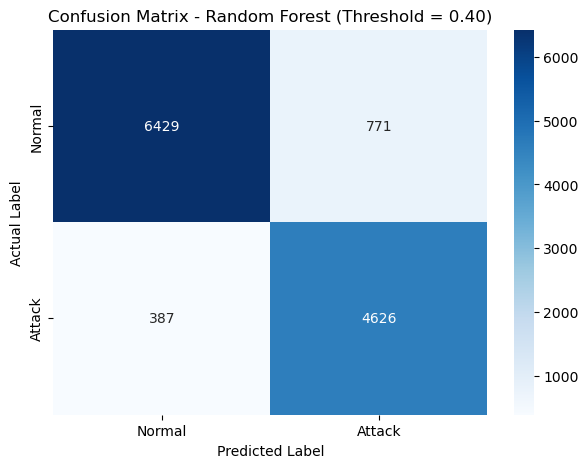

In [305]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

threshold = 0.40

# Probability from the final model.
y_prob_final = rf_final.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob_final >= threshold).astype(int)

cm_final = confusion_matrix(y_test, y_pred_final)

print(cm_final)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Random Forest (Threshold = 0.40)")
plt.show()

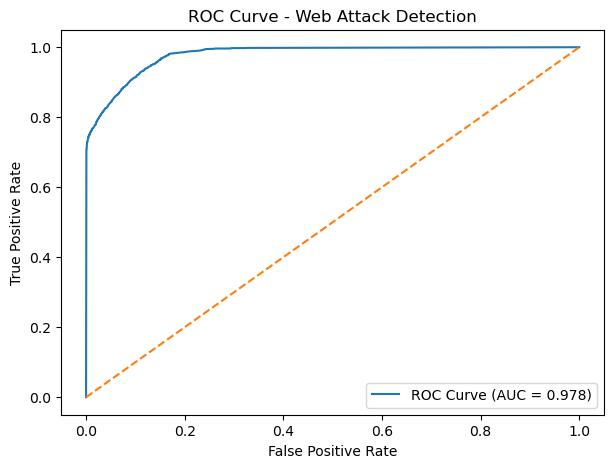

ROC-AUC: 0.9780789530553893


In [309]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, y_prob_final)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Web Attack Detection")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc)

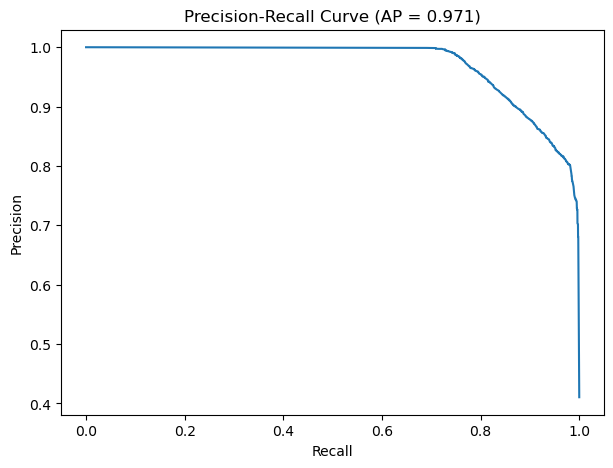

Average Precision: 0.970770021583613


In [310]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(
    y_test,
    y_prob_final
)

avg_precision = average_precision_score(
    y_test,
    y_prob_final
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve (AP = {avg_precision:.3f})")
plt.show()

print("Average Precision:", avg_precision)

In [258]:
print(type(rf_final))
print(len(rf_final.feature_importances_))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
24


In [259]:
print(rf_final.feature_names_in_)

['url_length' 'parameter_count' 'special_char_count' 'encoding_count'
 'dot_count' 'question_mark_count' 'content_length'
 'content_encoded_count' 'is_form_urlencoded' 'sql_keyword_count'
 'sql_comment_count' 'sql_logic_count' 'query_sql_keyword_count'
 'xss_angle_bracket_count' 'xss_parentheses_count'
 'javascript_keyword_count' 'dot_dot_count' 'etc_passwd_indicator'
 'ssi_exec_indicator' 'method_post' 'method_put'
 'suspicious_path_keyword_count' 'sensitive_endpoint_indicator'
 'url_entropy']


In [260]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": rf_final.feature_names_in_,
    "Importance": rf_final.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance)

                          Feature  Importance
23                    url_entropy    0.270244
0                      url_length    0.224497
6                  content_length    0.155949
4                       dot_count    0.080691
7           content_encoded_count    0.074356
3                  encoding_count    0.044489
2              special_char_count    0.037201
1                 parameter_count    0.021420
8              is_form_urlencoded    0.021246
19                    method_post    0.017222
5             question_mark_count    0.011061
14          xss_parentheses_count    0.008724
13        xss_angle_bracket_count    0.007400
10              sql_comment_count    0.007027
20                     method_put    0.006600
21  suspicious_path_keyword_count    0.003328
22   sensitive_endpoint_indicator    0.002951
11                sql_logic_count    0.001870
9               sql_keyword_count    0.001830
18             ssi_exec_indicator    0.000798
12        query_sql_keyword_count 

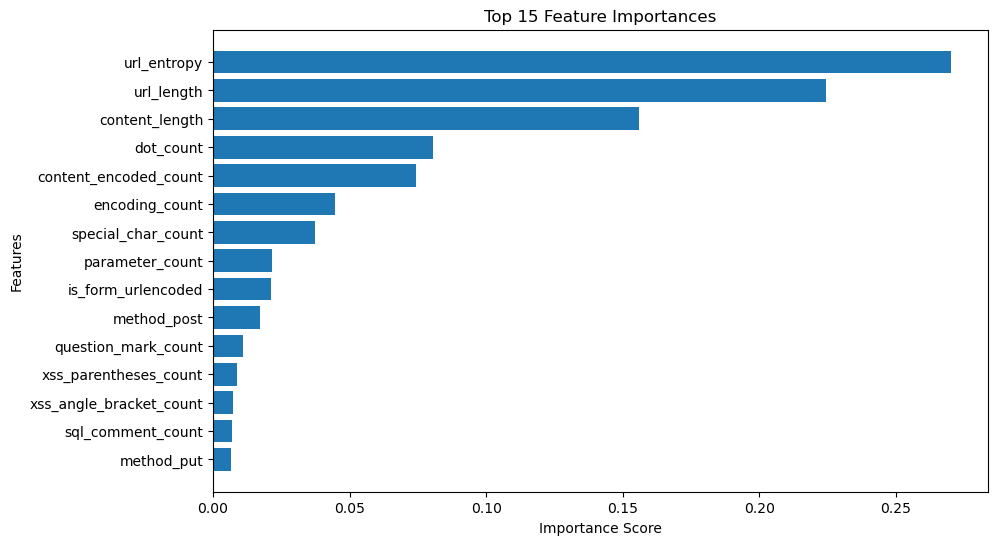

In [261]:
top_features = importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importances")
plt.gca().invert_yaxis()

plt.show()

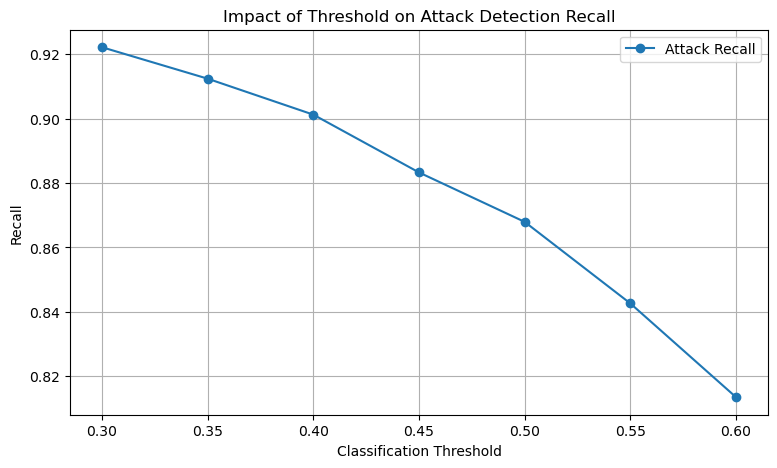

In [262]:
threshold_results = pd.DataFrame({
    "Threshold": [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60],
    "Accuracy": [0.876197, 0.880291, 0.884713, 0.890117, 0.890035, 0.890445, 0.888479],
    "Recall": [0.922202, 0.912428, 0.901257, 0.883303, 0.867943, 0.842609, 0.813485],
    "False_Negatives": [390, 439, 495, 585, 662, 789, 935]
})

plt.figure(figsize=(9, 5))
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Attack Recall"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Recall")
plt.title("Impact of Threshold on Attack Detection Recall")
plt.legend()
plt.grid()

plt.show()

In [263]:
import joblib

joblib.dump(rf_final, "deeplog_web_attack_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [264]:
joblib.dump(
    list(X_train.columns),
    "deeplog_features.pkl"
)

print("Feature list saved successfully!")

Feature list saved successfully!


In [346]:
model = rf_final
features = list(X_train.columns)


def predict_attack(feature_data, threshold=0.45):
    input_df = pd.DataFrame([feature_data]).reindex(
        columns=features,
        fill_value=0
    )

    probability = float(model.predict_proba(input_df)[0, 1])
    prediction = int(probability >= threshold)

    return {
        "prediction": "Attack" if prediction else "Normal",
        "attack_probability": round(probability, 4),
        "threshold": threshold
    }

In [266]:
sample = {
    feature: 0 for feature in features
}

result = predict_attack(sample)

print(result)

{'prediction': 'Attack', 'attack_probability': 1.0, 'threshold': 0.4}


In [344]:
import math
import re
from collections import Counter
from urllib.parse import parse_qsl, unquote, urlparse


def calculate_entropy(text):
    if not text:
        return 0.0

    counts = Counter(text)
    length = len(text)
    return -sum(
        (count / length) * math.log2(count / length)
        for count in counts.values()
    )


def clean_input(value):
    if value is None or pd.isna(value):
        return ""
    return str(value)


def extract_features(url, method="GET", content="", content_type=""):
    raw_url = clean_input(url)
    url = re.sub(r"\s+HTTP/\d(?:\.\d)?$", "", raw_url, flags=re.IGNORECASE)
    method = clean_input(method).upper()
    content = clean_input(content)
    content_type = clean_input(content_type)

    parsed = urlparse(url)
    decoded_url = unquote(url)
    lower_url = decoded_url.lower()
    query = parsed.query
    query_params = parse_qsl(query, keep_blank_values=True)
    path = unquote(parsed.path).lower()
    sql_keywords = ["select", "union", "insert", "delete", "update", "drop"]

    return {
        "url_length": len(url),
        "parameter_count": len(query_params),
        "special_char_count": len(re.findall(r"[<>'\";]", decoded_url)),
        "encoding_count": url.count("%"),
        "dot_count": url.count("."),
        "question_mark_count": url.count("?"),
        "content_length": len(content),
        "content_encoded_count": content.count("%"),
        "is_form_urlencoded": int("application/x-www-form-urlencoded" in content_type.lower()),
        "sql_keyword_count": sum(lower_url.count(keyword) for keyword in sql_keywords),
        "sql_comment_count": decoded_url.count("--") + decoded_url.count("/*") + decoded_url.count("*/"),
        "sql_logic_count": lower_url.count(" or ") + lower_url.count(" and "),
        "query_sql_keyword_count": sum(unquote(query).lower().count(keyword) for keyword in sql_keywords),
        "xss_angle_bracket_count": decoded_url.count("<") + decoded_url.count(">"),
        "xss_parentheses_count": decoded_url.count("(") + decoded_url.count(")"),
        "javascript_keyword_count": sum(lower_url.count(keyword) for keyword in ["javascript", "alert", "onerror", "onload", "script"]),
        "dot_dot_count": decoded_url.count("../"),
        "etc_passwd_indicator": int("/etc/passwd" in lower_url),
        "ssi_exec_indicator": int("exec" in lower_url),
        "method_post": int(method == "POST"),
        "method_put": int(method == "PUT"),
        "suspicious_path_keyword_count": sum(path.count(keyword) for keyword in ["admin", "login", "register", "edit", "upload", "config", "shell"]),
        "sensitive_endpoint_indicator": int(any(keyword in path for keyword in ["admin", "administrator", "login", "wp-admin", "phpmyadmin"])),
        "url_entropy": calculate_entropy(decoded_url),
    }

In [311]:
url = "http://example.com/login?id=1"

feature_data = extract_features(url)

result = predict_attack(feature_data)

print(result)

{'prediction': 'Attack', 'attack_probability': 1.0, 'threshold': 0.4}


In [ ]:
test_urls_normal = [
    "https://www.google.com",
    "https://example.com",
    "https://www.wikipedia.org/wiki/Machine_learning",
    "https://www.amazon.in/products",
    "https://example.com/products?id=123",
    "https://example.com/about",
    "https://example.com/contact",
    "https://example.org/blog/python-tutorial",
    "https://www.github.com/openai",
    "https://example.com/search?q=laptop"
]


In [319]:
test_urls_attack = [
    "https://example.test/search?q=%27%20OR%20%271%27%3D%271",
    "https://example.test/page?id=1%20UNION%20SELECT%20NULL",
    "https://example.test/search?q=%3Cscript%3Ealert(1)%3C/script%3E",
    "https://example.test/file?path=../../../../etc/passwd",
    "https://example.test/page?cmd=cat%20/etc/passwd",
    "https://example.test/login?user=admin%27--",
]

In [348]:
for url in test_urls_normal + test_urls_attack:
    feature_data = extract_features(url, method="GET")

    result = predict_attack(feature_data)

    print("\nURL:", url)
    print("Prediction:", result["prediction"])
    print("Probability:", result["attack_probability"])


URL: https://www.google.com
Prediction: Normal
Probability: 0.2756

URL: https://example.com
Prediction: Normal
Probability: 0.2756

URL: https://www.wikipedia.org/wiki/Machine_learning
Prediction: Normal
Probability: 0.2756

URL: https://www.amazon.in/products
Prediction: Normal
Probability: 0.2756

URL: https://example.com/products?id=123
Prediction: Normal
Probability: 0.4001

URL: https://example.com/about
Prediction: Normal
Probability: 0.2756

URL: https://example.com/contact
Prediction: Normal
Probability: 0.2756

URL: https://example.org/blog/python-tutorial
Prediction: Normal
Probability: 0.2756

URL: https://www.github.com/openai
Prediction: Normal
Probability: 0.2756

URL: https://example.com/search?q=laptop
Prediction: Normal
Probability: 0.4001

URL: https://example.test/search?q=%27%20OR%20%271%27%3D%271
Prediction: Attack
Probability: 1.0

URL: https://example.test/page?id=1%20UNION%20SELECT%20NULL
Prediction: Attack
Probability: 0.7377

URL: https://example.test/search